# Evaluación Sumativa 1 — Código del informe
## Dataset: *E-Commerce Shipping Data* (entregas atrasadas)

**MCDI501 - Estadística Computacional para la Toma de Decisiones**
Magíster en Ciencia de Datos e Inteligencia Artificial, Universidad Andrés Bello
Equipo: José Ignacio Rodríguez, Yerko Gallardo y Sebastián Rojas

Este cuaderno reproduce los resultados del informe y sigue su mismo orden:

0. Configuración y carga de datos
1. Estadística descriptiva (ID1.2): tipos de variables, medidas resumen, frecuencias, calidad de datos y análisis exploratorio (EDA)
2. Estimación puntual e intervalos de confianza (ID1.3)
3. Pruebas de hipótesis (ID1.4)
4. Síntesis

## 0. Configuración y carga de datos

El archivo original `data/raw/ecommerce_shipping.csv` no se modifica. La base de trabajo `df` solo cambia
los nombres de las columnas y agrega `entrega_atrasada` (1 = atrasada, 0 = a tiempo). No se eliminan filas.

In [1]:
from pathlib import Path
import pandas as pd
from scipy import stats
import hashlib
from importlib.metadata import version

# Raíz del proyecto: funciona al ejecutar desde la raíz o desde notebooks/
ubicacion = Path.cwd().resolve()
candidatas = [p for a in [ubicacion, *ubicacion.parents] for p in [a, a / 'sumativa_1']]
RAIZ = next((p for p in candidatas if (p / 'notebooks/sumativa_1.ipynb').is_file()
             and (p / 'data/raw/ecommerce_shipping.csv').is_file()), None)
if RAIZ is None:
    raise FileNotFoundError('Ejecute desde el repositorio, sumativa_1/ o sus notebooks/.')
HUELLA_INICIAL = hashlib.sha256((RAIZ / 'data/raw/ecommerce_shipping.csv').read_bytes()).hexdigest()

raw = pd.read_csv(RAIZ / 'data/raw/ecommerce_shipping.csv', encoding='utf-8-sig')

NOMBRES = {
    'ID': 'id_envio', 'Warehouse_block': 'bloque_bodega', 'Mode_of_Shipment': 'modalidad_envio',
    'Customer_care_calls': 'llamadas_atencion', 'Customer_rating': 'calificacion_cliente',
    'Cost_of_the_Product': 'costo_producto', 'Prior_purchases': 'compras_previas',
    'Product_importance': 'importancia_producto', 'Gender': 'genero',
    'Discount_offered': 'descuento_ofrecido', 'Weight_in_gms': 'peso_gramos',
}
TARGET = 'entrega_atrasada'

df = raw.rename(columns=NOMBRES)
df[TARGET] = raw['Reached.on.Time_Y.N']
df['importancia_producto'] = pd.Categorical(df['importancia_producto'],
                                            categories=['low', 'medium', 'high'], ordered=True)

n = len(df)
print('Dimensiones:', df.shape)
df.head()

Dimensiones: (10999, 13)


,id_envio,bloque_bodega,modalidad_envio,llamadas_atencion,calificacion_cliente,costo_producto,compras_previas,importancia_producto,genero,descuento_ofrecido,peso_gramos,Reached.on.Time_Y.N,entrega_atrasada
0,1,D,Flight,4,2,177,3,low,F,44,1233,1,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1,1


## 1. Estadística descriptiva (ID1.2)

### 1.1 Tipos de variables y medidas resumen
Doce variables: un identificador, el resultado binario (`entrega_atrasada`), cinco cuantitativas (llamadas,
costo, compras previas, descuento y peso), tres nominales (bodega, modalidad y género) y dos ordinales
(calificación e importancia). La columna original del resultado (`Reached.on.Time_Y.N`) se conserva en `df`.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   id_envio              10999 non-null  int64   
 1   bloque_bodega         10999 non-null  str     
 2   modalidad_envio       10999 non-null  str     
 3   llamadas_atencion     10999 non-null  int64   
 4   calificacion_cliente  10999 non-null  int64   
 5   costo_producto        10999 non-null  int64   
 6   compras_previas       10999 non-null  int64   
 7   importancia_producto  10999 non-null  category
 8   genero                10999 non-null  str     
 9   descuento_ofrecido    10999 non-null  int64   
 10  peso_gramos           10999 non-null  int64   
 11  Reached.on.Time_Y.N   10999 non-null  int64   
 12  entrega_atrasada      10999 non-null  int64   
dtypes: category(1), int64(9), str(3)
memory usage: 1.1 MB


In [3]:
tipos = pd.Series({
    'id_envio': 'Identificador (nominal)',
    'bloque_bodega': 'Cualitativa nominal',
    'modalidad_envio': 'Cualitativa nominal',
    'llamadas_atencion': 'Cuantitativa discreta (conteo)',
    'calificacion_cliente': 'Cualitativa ordinal (1 a 5)',
    'costo_producto': 'Cuantitativa de razón (USD)',
    'compras_previas': 'Cuantitativa discreta (conteo)',
    'importancia_producto': 'Cualitativa ordinal (low < medium < high)',
    'genero': 'Cualitativa nominal',
    'descuento_ofrecido': 'Cuantitativa (unidad no especificada)',
    'peso_gramos': 'Cuantitativa de razón (gramos)',
    'entrega_atrasada': 'Nominal binaria (resultado; 1 = atrasada)',
}, name='Tipo')
tipos.to_frame()

,Tipo
id_envio,Identificador (nominal)
bloque_bodega,Cualitativa nominal
modalidad_envio,Cualitativa nominal
llamadas_atencion,Cuantitativa discreta (conteo)
calificacion_cliente,Cualitativa ordinal (1 a 5)
costo_producto,Cuantitativa de razón (USD)
compras_previas,Cuantitativa discreta (conteo)
importancia_producto,Cualitativa ordinal (low < medium < high)
genero,Cualitativa nominal
descuento_ofrecido,Cuantitativa (unidad no especificada)


#### Clasificación semántica de las variables
La clasificación se toma del significado y la escala documentados en el diccionario, no del número de valores distintos. Una variable numérica con pocos valores puede ser un conteo; la unicidad tampoco basta para declarar un identificador. Las listas se derivan de la tabla `tipos` y se verifican contra las columnas cargadas.


In [4]:
ids = tipos[tipos.str.startswith('Identificador')].index.tolist()
cuantitativas = tipos[tipos.str.startswith('Cuantitativa')].index.tolist()
cualitativas = tipos[tipos.str.startswith('Cualitativa')].index.tolist()
assert set(ids + cuantitativas + cualitativas + [TARGET]) <= set(df.columns)
assert set(cuantitativas).isdisjoint(cualitativas)
print('Identificador:', ids)
print('Cuantitativas:', cuantitativas)
print('Cualitativas:', cualitativas)


Identificador: ['id_envio']
Cuantitativas: ['llamadas_atencion', 'costo_producto', 'compras_previas', 'descuento_ofrecido', 'peso_gramos']
Cualitativas: ['bloque_bodega', 'modalidad_envio', 'calificacion_cliente', 'importancia_producto', 'genero']


Medidas de centro, dispersión y forma. Se calcula asimetría de Fisher-Pearson ajustada con `scipy.stats.skew(bias=False)` y exceso de curtosis de Fisher con `scipy.stats.kurtosis(fisher=True, bias=False)`. La referencia normal es 0 para ambas; estos coeficientes no prueban normalidad ni resumen por sí solos una distribución bimodal.


In [5]:
desc = df[cuantitativas].describe().T
desc['IQR'] = desc['75%'] - desc['25%']
desc['asimetria'] = df[cuantitativas].apply(lambda s: stats.skew(s, bias=False, nan_policy='omit'))
desc['curtosis_exceso'] = df[cuantitativas].apply(lambda s: stats.kurtosis(s, fisher=True, bias=False, nan_policy='omit'))

(RAIZ / 'outputs/tablas').mkdir(parents=True, exist_ok=True)
desc.to_csv(RAIZ / 'outputs/tablas/descriptiva_cuantitativas.csv', encoding='utf-8')
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,IQR,asimetria,curtosis_exceso
llamadas_atencion,10999.0,4.05,1.14,2.0,3.0,4.0,5.0,7.0,2.0,0.39,-0.31
costo_producto,10999.0,210.20,48.06,96.0,169.0,214.0,251.0,310.0,82.0,-0.16,-0.97
compras_previas,10999.0,3.57,1.52,2.0,3.0,3.0,4.0,10.0,1.0,1.68,4.01
descuento_ofrecido,10999.0,13.37,16.21,1.0,4.0,7.0,10.0,65.0,6.0,1.80,2.00
peso_gramos,10999.0,3634.02,1635.38,1001.0,1839.5,4149.0,5050.0,7846.0,3210.5,-0.25,-1.45


### 1.2 Frecuencias de las variables cualitativas
Frecuencias absolutas y porcentajes, con las ordinales en su orden natural. Resultado exportado a
`outputs/tablas/frecuencias.csv`.

In [6]:
partes = []
for v in [TARGET] + cualitativas:
    t = df[v].value_counts().sort_index().rename('n').to_frame()   # respeta el orden de las ordinales
    t['porcentaje'] = t['n'] / n * 100
    t.insert(0, 'categoria', t.index.astype(str))
    t.insert(0, 'variable', v)
    assert t['n'].sum() == n          # las frecuencias suman el total
    partes.append(t)

frecuencias = pd.concat(partes, ignore_index=True)
frecuencias.to_csv(RAIZ / 'outputs/tablas/frecuencias.csv', index=False, encoding='utf-8')

r = df['calificacion_cliente']
print(f"Calificación: mediana = {r.median():g}, Q1 = {r.quantile(0.25):g}, Q3 = {r.quantile(0.75):g}")
cod = int(df['importancia_producto'].cat.codes.median())
print(f"Importancia : mediana = {df['importancia_producto'].cat.categories[cod]}")
frecuencias.round(2)

Calificación: mediana = 3, Q1 = 2, Q3 = 4
Importancia : mediana = medium


,variable,categoria,n,porcentaje
0,entrega_atrasada,0,4436,40.33
1,entrega_atrasada,1,6563,59.67
2,bloque_bodega,A,1833,16.67
3,bloque_bodega,B,1833,16.67
4,bloque_bodega,C,1833,16.67
5,bloque_bodega,D,1834,16.67
6,bloque_bodega,F,3666,33.33
7,modalidad_envio,Flight,1777,16.16
8,modalidad_envio,Road,1760,16.00
9,modalidad_envio,Ship,7462,67.84


### 1.3 Calidad de datos
Nulos, duplicados, unicidad del identificador y tasa de atraso.

In [7]:
sin_id = [c for c in raw.columns if c != 'ID']

print(f"Registros                  : {n:,}")
print(f"Celdas vacías              : {raw.isna().sum().sum()}")
print(f"ID únicos                  : {df['id_envio'].nunique():,}")
print(f"Duplicados con ID          : {raw.duplicated().sum()}")
print(f"Duplicados sin ID          : {raw.duplicated(subset=sin_id).sum()}")
print(f"Entregas atrasadas         : {df[TARGET].sum():,} ({df[TARGET].mean()*100:.1f}%)")
print(f"Entregas a tiempo          : {(df[TARGET] == 0).sum():,} ({(1 - df[TARGET].mean())*100:.1f}%)")
print('Bodegas:', df['bloque_bodega'].value_counts().sort_index().to_dict())

Registros                  : 10,999
Celdas vacías              : 0
ID únicos                  : 10,999
Duplicados con ID          : 0
Duplicados sin ID          : 0
Entregas atrasadas         : 6,563 (59.7%)
Entregas a tiempo          : 4,436 (40.3%)
Bodegas: {'A': 1833, 'B': 1833, 'C': 1833, 'D': 1834, 'F': 3666}


### 1.4 Tabla de controles
Resumen de los controles, exportado a `outputs/tablas/calidad_datos.csv`. Estados: OK, ALERTA (revisar) e
INFO (extremos válidos, no es un error).

In [8]:
filas = []
def control(nombre, variable, esperado, observado, ok, detalle=''):
    filas.append((nombre, variable, esperado, observado, 'OK' if ok else 'ALERTA', detalle))

control('filas', 'todas', n, len(df), len(df) == n, 'Sin exclusiones de filas')
control('nulos_totales', 'todas', 0, int(raw.isna().sum().sum()), raw.isna().sum().sum() == 0, 'Sin imputación ni faltantes artificiales')
control('id_unico', 'id_envio', n, int(df['id_envio'].nunique()), df['id_envio'].is_unique, 'No prueba independencia ni un registro por cliente')

dominios = {'bloque_bodega': ['A', 'B', 'C', 'D', 'F'], 'modalidad_envio': ['Flight', 'Road', 'Ship'], 'genero': ['F', 'M']}
for v, esperado in dominios.items():
    obs = sorted(df[v].unique())
    control('dominio_categorico', v, esperado, obs, obs == esperado, 'F no se recodifica a E' if v == 'bloque_bodega' else '')
    control('suma_frecuencias', v, n, int(df[v].value_counts().sum()), df[v].value_counts().sum() == n)

obs = sorted(df['importancia_producto'].dropna().astype(str).unique())
control('dominio_ordinal', 'importancia_producto', 'low<medium<high', obs, obs == ['high', 'low', 'medium'])
control('dominio_ordinal', 'calificacion_cliente', '1..5', f"{df['calificacion_cliente'].min()}..{df['calificacion_cliente'].max()}", df['calificacion_cliente'].between(1, 5).all())
control('resultado_binario', TARGET, '{0,1}', sorted(df[TARGET].unique().tolist()), set(df[TARGET]) <= {0, 1},
        f"1 (atrasada)={df[TARGET].sum()}; 0 (a tiempo)={(df[TARGET] == 0).sum()}")
control('alias_igual_original', TARGET, 0, int((df[TARGET] != raw['Reached.on.Time_Y.N']).sum()), (df[TARGET] == raw['Reached.on.Time_Y.N']).all())

numericas = ['llamadas_atencion', 'costo_producto', 'compras_previas', 'descuento_ofrecido', 'peso_gramos']
for v in numericas:
    s = df[v]
    q1, q3 = s.quantile([0.25, 0.75])
    bajo, alto = int((s < q1 - 1.5 * (q3 - q1)).sum()), int((s > q3 + 1.5 * (q3 - q1)).sum())
    control('rango_valido', v, '>0', f'{s.min()}..{s.max()}', (s > 0).all())
    filas.append(('extremos_regla_IQR', v, 'conservar', f'bajo={bajo}; alto={alto}', 'INFO' if bajo + alto else 'OK',
                  'Valores válidos; no se eliminan' if bajo + alto else ''))

control('duplicados_con_ID', 'todas', 0, int(raw.duplicated().sum()), not raw.duplicated().any())
control('duplicados_sin_ID', 'todas menos ID', 0, int(raw.duplicated(subset=sin_id).sum()), not raw.duplicated(subset=sin_id).any(),
        'Perfiles idénticos no se eliminan automáticamente')

calidad = pd.DataFrame(filas, columns=['control', 'variable', 'esperado', 'observado', 'estado', 'detalle'])
(RAIZ / 'outputs/tablas').mkdir(parents=True, exist_ok=True)
calidad.to_csv(RAIZ / 'outputs/tablas/calidad_datos.csv', index=False, encoding='utf-8')

print(calidad['estado'].value_counts().to_dict())
calidad[['control', 'variable', 'observado', 'estado']]

{'OK': 23, 'INFO': 2}


,control,variable,observado,estado
0,filas,todas,10999,OK
1,nulos_totales,todas,0,OK
2,id_unico,id_envio,10999,OK
3,dominio_categorico,bloque_bodega,"[A, B, C, D, F]",OK
4,suma_frecuencias,bloque_bodega,10999,OK
5,dominio_categorico,modalidad_envio,"[Flight, Road, Ship]",OK
6,suma_frecuencias,modalidad_envio,10999,OK
7,dominio_categorico,genero,"[F, M]",OK
8,suma_frecuencias,genero,10999,OK
9,dominio_ordinal,importancia_producto,"[high, low, medium]",OK


### 1.5 Análisis exploratorio (EDA)
Orden: (a) variable dependiente, (b) cuantitativas independientes, (c) cualitativas independientes,
(d) relaciones entre cuantitativas, (e) relación de la variable dependiente con cada predictora,
(f) interacción descuento × peso, (g) asociación entre cualitativas y (h) síntesis.
Los identificadores se excluyen. Las figuras se exportan a `outputs/figuras/fig_eda_*` en PDF (vectorial,
para el informe) y PNG (vista rápida).

#### Estilo de las figuras
- **Tamaño de impresión:** cada figura se dibuja al ancho de texto del informe (`ANCHO` = 6,3 pulgadas) o a
  dos tercios (`ANCHO_MEDIO`), así la fuente queda en 8–9 pt dentro del PDF.
- **Color con significado fijo:** azul = entrega a tiempo, terracota = entrega atrasada, gris = referencia
  (tasa global, medias, umbrales). Las series que no son grupos del resultado se distinguen por forma.
- **Etiquetas en español** (`ETIQ_VAR`, `ETIQ_CAT`) y números con formato es-CL (`num`: 10.999; 59,7).
- **Incertidumbre visible:** toda tasa de atraso por grupo lleva su IC de Wilson al 95 % (`tasa_por`).
- **Sin título interno:** el mensaje va en el *caption* del informe; los paneles solo nombran la variable.

In [9]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

AZUL  = '#1f5f8b'   # entregas a tiempo / serie principal
TERRA = '#d1603d'   # entregas atrasadas
GRIS  = '#555555'   # referencias: tasa global, medias, umbrales
BG    = '#ffffff'   # fondo de los ejes
GRID  = '#e1e4e8'   # líneas de grilla

ANCHO, ANCHO_MEDIO = 6.3, 4.2   # pulgadas: ancho de texto del informe y 2/3 de él

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'pdf.fonttype': 42,
    'figure.constrained_layout.use': True,
    'font.family': 'serif', 'font.size': 9,
    'axes.titlesize': 9, 'axes.labelsize': 8.5, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8, 'legend.frameon': False,
    'axes.facecolor': BG, 'axes.edgecolor': '#8c8578',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'normal', 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
})
(RAIZ / 'outputs/figuras').mkdir(parents=True, exist_ok=True)

In [10]:
import numpy as np
import seaborn as sns
from scipy.stats.contingency import association
from matplotlib.lines import Line2D
from statsmodels.stats.proportion import proportion_confint

ETIQ_TARGET = {0: 'A tiempo (0)', 1: 'Atrasada (1)'}
PAL_TARGET = {ETIQ_TARGET[0]: AZUL, ETIQ_TARGET[1]: TERRA}
tasa_global = df[TARGET].mean()

ETIQ_VAR = {
    'llamadas_atencion': 'Llamadas a atención', 'costo_producto': 'Costo (USD)',
    'compras_previas': 'Compras previas', 'descuento_ofrecido': 'Descuento ofrecido',
    'peso_gramos': 'Peso (g)', 'bloque_bodega': 'Bloque de bodega',
    'modalidad_envio': 'Modalidad de envío', 'calificacion_cliente': 'Calificación del cliente',
    'importancia_producto': 'Importancia del producto', 'genero': 'Género', TARGET: 'Entrega atrasada',
}
ETIQ_CORTA = {
    'llamadas_atencion': 'Llamadas', 'costo_producto': 'Costo', 'compras_previas': 'Compras previas',
    'descuento_ofrecido': 'Descuento', 'peso_gramos': 'Peso', 'bloque_bodega': 'Bodega',
    'modalidad_envio': 'Modalidad', 'calificacion_cliente': 'Calificación',
    'importancia_producto': 'Importancia', 'genero': 'Género',
}
ETIQ_CAT = {
    'modalidad_envio': {'Flight': 'Avión', 'Road': 'Carretera', 'Ship': 'Barco'},
    'importancia_producto': {'low': 'Baja', 'medium': 'Media', 'high': 'Alta'},
    'genero': {'F': 'Femenino', 'M': 'Masculino'},
}


def etiq(v):
    return ETIQ_VAR.get(v, v)


def etiq_cat(v, valores):
    m = ETIQ_CAT.get(v, {})
    return [m.get(str(x), str(x)) for x in valores]


def num(x, dec=0):
    '''Número con formato es-CL: punto de miles y coma decimal.'''
    return f'{x:,.{dec}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


FMT_MILES = FuncFormatter(lambda x, _: num(x))
FMT_PCT = FuncFormatter(lambda x, _: f'{num(x)}%')


def tasa_por(grupo):
    '''Tasa de atraso (%) por grupo con IC de Wilson al 95 %.'''
    t = df[TARGET].groupby(grupo, observed=True).agg(['sum', 'size'])
    li, ls = proportion_confint(t['sum'], t['size'], alpha=0.05, method='wilson')
    return pd.DataFrame({'tasa': t['sum'] / t['size'] * 100, 'li': li * 100, 'ls': ls * 100, 'n': t['size']})


def etiq_tramos(indice):
    '''Etiquetas legibles para tramos de pd.qcut sobre variables enteras: (95.999, 161.0] -> 96–161.'''
    return [f'{num(np.floor(iv.left) + 1)}–{num(iv.right)}' if isinstance(iv, pd.Interval) else str(iv)
            for iv in indice]


def rejilla(k, ncols=3, alto=1.9, ancho_total=ANCHO, **kw):
    '''Figura con k paneles en ncols columnas al ancho del informe; devuelve también los ejes sobrantes.'''
    nfilas = int(np.ceil(k / ncols))
    fig, ax = plt.subplots(nfilas, ncols, figsize=(ancho_total, alto * nfilas), squeeze=False, **kw)
    return fig, ax.flat[:k], ax.flat[k:]


def guardar(nombre, fig=None, formatos=('pdf', 'png')):
    '''Exporta la figura en PDF (vectorial, para LaTeX) y PNG (vista rápida).'''
    fig = fig or plt.gcf()
    for ext in formatos:
        fig.savefig(RAIZ / f'outputs/figuras/{nombre}.{ext}')
    plt.show()

#### (a) Variable dependiente: `entrega_atrasada`
Barra apilada al 100 % con la frecuencia absoluta y relativa de cada resultado; la línea punteada marca el
50 %. El desbalance (≈60/40) es moderado: no impide comparar grupos, pero las tasas por categoría deben
leerse contra la tasa global.

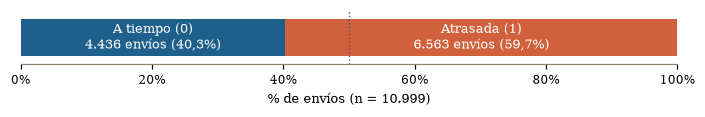

In [11]:
conteo = df[TARGET].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(ANCHO, 0.95))
izq = 0
for k, color in [(0, AZUL), (1, TERRA)]:
    p = conteo[k] / n * 100
    ax.barh(0, p, left=izq, color=color, height=0.7)
    ax.text(izq + p / 2, 0, f'{ETIQ_TARGET[k]}\n{num(conteo[k])} envíos ({num(p, 1)}%)',
            ha='center', va='center', color='white', fontsize=8.5)
    izq += p
ax.axvline(50, color=GRIS, ls=':', lw=0.9)
ax.set_xlim(0, 100)
ax.set_ylim(-0.5, 0.5)
ax.xaxis.set_major_formatter(FMT_PCT)
ax.set_xlabel('% de envíos (n = ' + num(n) + ')')
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.grid(False)
guardar('fig_eda_1_dependiente')

#### (b) Variables independientes cuantitativas
Histograma (% de envíos) y diagrama de caja por variable. Las de conteo o con pocos valores enteros se
grafican con un bin por valor. No se superpone densidad *kernel*: en variables acotadas o bimodales (peso)
el KDE inventa masa fuera del soporte. Líneas: media (discontinua) y mediana (continua).

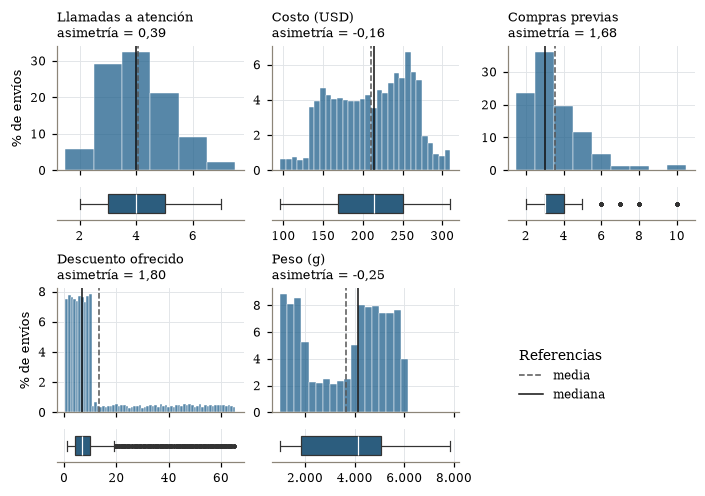

In [12]:
fig = plt.figure(figsize=(ANCHO, 4.4))
gs = fig.add_gridspec(4, 3, height_ratios=[3, 0.8, 3, 0.8])
posiciones = [(0, 0), (0, 1), (0, 2), (2, 0), (2, 1)]
for (r, c), v in zip(posiciones, cuantitativas):
    s = df[v]
    a_h = fig.add_subplot(gs[r, c])
    a_b = fig.add_subplot(gs[r + 1, c], sharex=a_h)
    discreta = pd.api.types.is_integer_dtype(s) and s.nunique() <= 70   # un bin por valor entero
    sns.histplot(s, ax=a_h, color=AZUL, discrete=discreta, stat='percent', edgecolor='white', linewidth=0.3)
    a_h.axvline(s.mean(), color=GRIS, lw=1, ls='--')
    a_h.axvline(s.median(), color='#111111', lw=1)
    a_h.set_title(f'{etiq(v)}\nasimetría = {num(s.skew(), 2)}', fontsize=8.5)
    a_h.set_xlabel('')
    a_h.set_ylabel('% de envíos' if c == 0 else '')
    a_h.tick_params(labelbottom=False)
    sns.boxplot(x=s, ax=a_b, color=AZUL, width=0.6, fliersize=1.5, linewidth=0.8,
                flierprops={'alpha': 0.4}, medianprops={'color': 'white'})
    a_b.set_xlabel('')
    a_b.set_yticks([])
    a_b.spines['left'].set_visible(False)
    a_b.grid(axis='y', visible=False)
    if s.max() >= 1000:
        a_b.xaxis.set_major_formatter(FMT_MILES)

a_leg = fig.add_subplot(gs[2:, 2])
a_leg.axis('off')
a_leg.legend(handles=[Line2D([], [], color=GRIS, lw=1, ls='--', label='media'),
                      Line2D([], [], color='#111111', lw=1, label='mediana')],
             loc='center left', title='Referencias', alignment='left')
guardar('fig_eda_2_cuantitativas')

#### (c) Variables independientes cualitativas
Frecuencia relativa de cada categoría. Las ordinales (`calificacion_cliente`, `importancia_producto`)
conservan su orden natural; las nominales se ordenan de mayor a menor frecuencia.

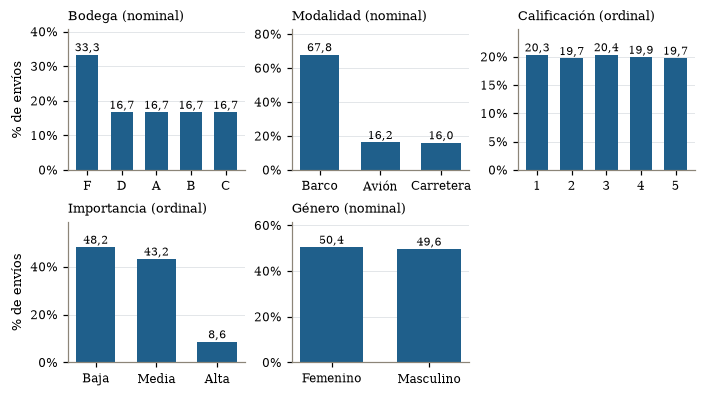

In [13]:
def es_ordinal(v):
    return isinstance(df[v].dtype, pd.CategoricalDtype) and df[v].cat.ordered or pd.api.types.is_numeric_dtype(df[v])

fig, ax, sobrantes = rejilla(len(cualitativas), alto=1.75)
for a in sobrantes:
    a.set_visible(False)
for j, (a, v) in enumerate(zip(ax, cualitativas)):
    frec = df[v].value_counts(normalize=True) * 100
    frec = frec.sort_index() if es_ordinal(v) else frec.sort_values(ascending=False)
    x = np.arange(len(frec))
    a.bar(x, frec.values, color=AZUL, width=0.65)
    for i, p in enumerate(frec.values):
        a.text(i, p + frec.max() * 0.03, num(p, 1), ha='center', fontsize=7)
    a.set_xticks(x, etiq_cat(v, frec.index))
    a.set_ylim(0, frec.max() * 1.22)
    a.yaxis.set_major_formatter(FMT_PCT)
    a.set_title(f"{ETIQ_CORTA[v]} ({'ordinal' if es_ordinal(v) else 'nominal'})", fontsize=8.5)
    a.set_ylabel('% de envíos' if j % 3 == 0 else '')
    a.grid(axis='x', visible=False)
guardar('fig_eda_3_cualitativas')

#### (d) Relaciones entre las variables cuantitativas
*Pairplot* de las cuantitativas coloreado por la variable dependiente (diagonal: densidades por grupo), y
matriz de correlación de Spearman (robusta a asimetría y a relaciones monótonas no lineales). El
*pairplot* tiene 11.000 puntos por panel, por lo que se exporta solo en PNG.

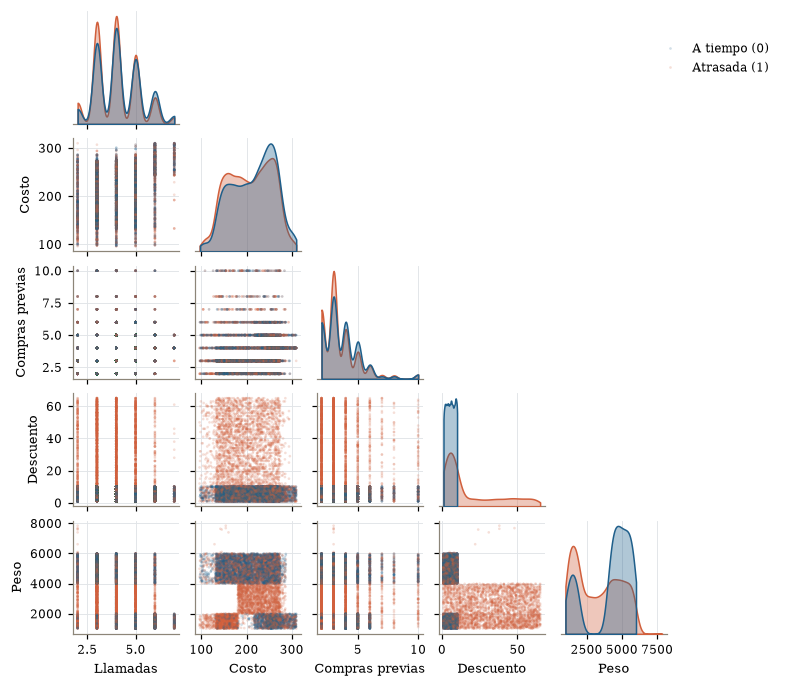

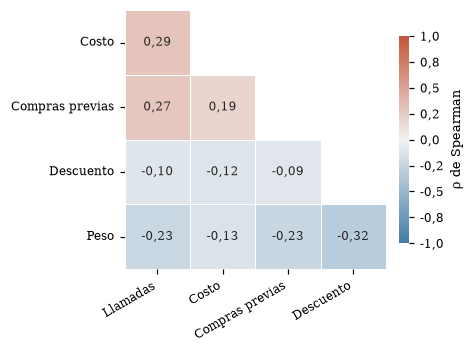

In [14]:
datos_pair = df[cuantitativas].assign(**{TARGET: df[TARGET].map(ETIQ_TARGET)})
with plt.rc_context({'figure.constrained_layout.use': False}):
    g = sns.pairplot(datos_pair, hue=TARGET, palette=PAL_TARGET, hue_order=list(ETIQ_TARGET.values()),
                     corner=True, height=ANCHO / len(cuantitativas),
                     plot_kws={'s': 3, 'alpha': 0.2, 'linewidth': 0, 'rasterized': True},
                     diag_kws={'common_norm': False, 'fill': True, 'alpha': 0.35, 'cut': 0})
    for a in g.axes.flat:
        if a is not None:
            a.set_xlabel(ETIQ_CORTA.get(a.get_xlabel(), a.get_xlabel()))
            a.set_ylabel(ETIQ_CORTA.get(a.get_ylabel(), a.get_ylabel()))
    g.legend.set_title('')
    sns.move_legend(g, 'upper right', bbox_to_anchor=(0.95, 0.95))
    guardar('fig_eda_4_pairplot', fig=g.figure, formatos=('png',))

corr = df[cuantitativas].corr(method='spearman')
vista_corr = corr.iloc[1:, :-1]   # triángulo inferior sin la diagonal de unos
fig, ax = plt.subplots(figsize=(ANCHO_MEDIO, 3.1))
sns.heatmap(vista_corr, mask=np.triu(np.ones_like(vista_corr, dtype=bool), k=1),
            annot=vista_corr.map(lambda x: num(x, 2)), fmt='', annot_kws={'fontsize': 8},
            cmap=sns.diverging_palette(240, 20, as_cmap=True), vmin=-1, vmax=1, center=0,
            linewidths=0.5, cbar_kws={'shrink': 0.8, 'label': 'ρ de Spearman', 'format': FuncFormatter(lambda x, _: num(x, 1))}, ax=ax)
ax.set_xticklabels([ETIQ_CORTA[c] for c in vista_corr.columns], rotation=30, ha='right')
ax.set_yticklabels([ETIQ_CORTA[c] for c in vista_corr.index], rotation=0)
ax.grid(False)
guardar('fig_eda_5_correlacion')

#### (e) Relación de la variable dependiente con las predictoras
**Cuantitativas.** Primera figura: tasa de atraso por valor (variables de conteo) o por quintil
(continuas), con su IC de Wilson al 95 % y la tasa global como referencia. Segunda figura: función de
distribución acumulada empírica (ECDF) de cada variable según el resultado; a diferencia del diagrama de
caja, muestra la distribución completa y funciona bien con variables discretas. La tabla resume medias y
medianas por grupo y la *d* de Cohen.

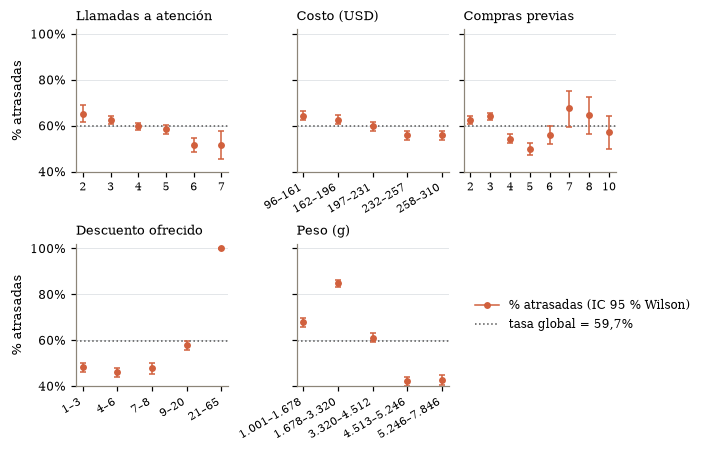

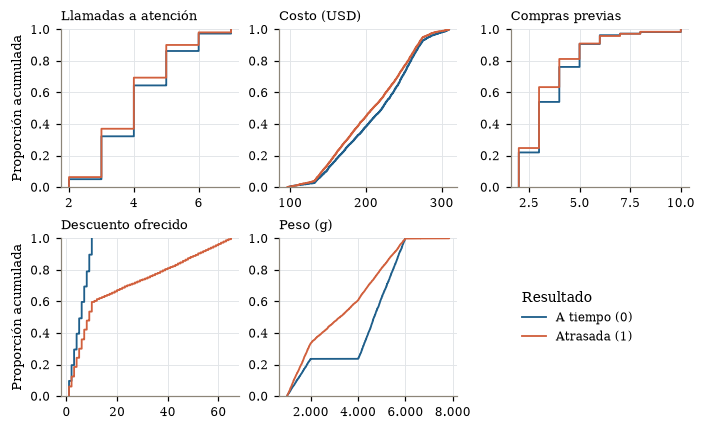

,media_a_tiempo,media_atrasada,mediana_a_tiempo,mediana_atrasada,d_cohen
variable,,,,,
descuento_ofrecido,5.546,18.664,6.0,9.0,0.882
peso_gramos,4168.668,3272.640,4674.0,3231.0,-0.569
costo_producto,214.499,207.289,222.0,209.0,-0.150
llamadas_atencion,4.148,3.991,4.0,4.0,-0.137
compras_previas,3.670,3.498,3.0,3.0,-0.113


In [15]:
def tramos(s):
    '''Valores originales si hay pocos; quintiles en otro caso.'''
    return s if s.nunique() <= 15 else pd.qcut(s, 5, duplicates='drop')

tasas_cuanti = {v: tasa_por(tramos(df[v])) for v in cuantitativas}
y_min = min(t['li'].min() for t in tasas_cuanti.values())
y_max = max(t['ls'].max() for t in tasas_cuanti.values())

fig, ax, sobrantes = rejilla(len(cuantitativas), alto=2.0, sharey=True)
for j, (a, v) in enumerate(zip(ax, cuantitativas)):
    t = tasas_cuanti[v]
    x = np.arange(len(t))
    a.axhline(tasa_global * 100, color=GRIS, ls=':', lw=1)
    a.errorbar(x, t['tasa'], yerr=[t['tasa'] - t['li'], t['ls'] - t['tasa']], fmt='o', ms=3.5,
               color=TERRA, ecolor=TERRA, elinewidth=1, capsize=2)
    rot = 30 if isinstance(t.index[0], pd.Interval) else 0
    a.set_xticks(x, etiq_tramos(t.index), rotation=rot, ha='right' if rot else 'center', fontsize=7)
    a.set_ylim(np.floor(y_min / 10) * 10, min(103, np.ceil(y_max / 10) * 10 + 2))
    a.yaxis.set_major_formatter(FMT_PCT)
    a.set_title(etiq(v), fontsize=8.5)
    a.set_ylabel('% atrasadas' if j % 3 == 0 else '')
    a.grid(axis='x', visible=False)
sobrantes[0].axis('off')
sobrantes[0].legend(handles=[
    Line2D([], [], color=TERRA, marker='o', ms=3.5, lw=1, label='% atrasadas (IC 95 % Wilson)'),
    Line2D([], [], color=GRIS, ls=':', lw=1, label=f'tasa global = {num(tasa_global * 100, 1)}%')],
    loc='center left')
guardar('fig_eda_6_dependiente_vs_cuantitativas')

fig, ax, sobrantes = rejilla(len(cuantitativas), alto=1.9)
for j, (a, v) in enumerate(zip(ax, cuantitativas)):
    for k in (0, 1):
        sns.ecdfplot(df.loc[df[TARGET] == k, v], ax=a, color=PAL_TARGET[ETIQ_TARGET[k]], lw=1.2,
                     label=ETIQ_TARGET[k])
    a.set_title(etiq(v), fontsize=8.5)
    a.set_xlabel('')
    a.set_ylabel('Proporción acumulada' if j % 3 == 0 else '')
    if df[v].max() >= 1000:
        a.xaxis.set_major_formatter(FMT_MILES)
sobrantes[0].axis('off')
sobrantes[0].legend(*ax[0].get_legend_handles_labels(), loc='center left', title='Resultado',
                    alignment='left')
guardar('fig_eda_6b_ecdf_por_resultado')

filas_rel = []
for v in cuantitativas:
    g0, g1 = df.loc[df[TARGET] == 0, v], df.loc[df[TARGET] == 1, v]
    sd_comb = np.sqrt(((len(g0) - 1) * g0.var() + (len(g1) - 1) * g1.var()) / (n - 2))
    filas_rel.append({'variable': v,
                      'media_a_tiempo': g0.mean(), 'media_atrasada': g1.mean(),
                      'mediana_a_tiempo': g0.median(), 'mediana_atrasada': g1.median(),
                      'd_cohen': (g1.mean() - g0.mean()) / sd_comb})
rel_cuanti = pd.DataFrame(filas_rel).set_index('variable')
rel_cuanti.to_csv(RAIZ / 'outputs/tablas/relacion_dependiente_cuantitativas.csv', encoding='utf-8')
rel_cuanti.sort_values('d_cohen', key=abs, ascending=False).round(3)

**Correlación de cada cuantitativa con el atraso.** Como la variable dependiente es binaria (0/1), la
correlación de Pearson equivale a la **punto-biserial**; se agrega la de **Spearman**, que usa rangos y es
robusta a la asimetría (descuento, compras previas) y a relaciones monótonas no lineales. El signo indica
la dirección: positivo = valores altos van con más atraso. Se informa el valor *p* como referencia
descriptiva; las pruebas formales están en la sección 3.

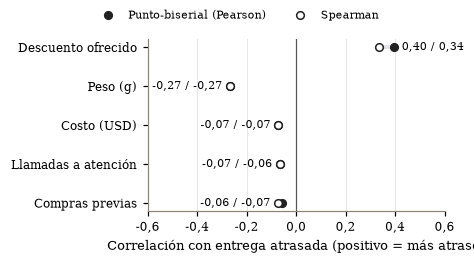

,r_punto_biserial,p_punto_biserial,rho_spearman,p_spearman
variable,,,,
descuento_ofrecido,0.397,0.0e+00,0.335,8.0e-287
peso_gramos,-0.269,2.4e-181,-0.266,1.9e-177
costo_producto,-0.074,1.1e-14,-0.072,4.5e-14
llamadas_atencion,-0.067,1.8e-12,-0.064,1.5e-11
compras_previas,-0.056,5.7e-09,-0.075,4.6e-15


In [16]:
from scipy.stats import pointbiserialr, spearmanr

filas_corr = []
for v in cuantitativas:
    r_pb, p_pb = pointbiserialr(df[TARGET], df[v])
    rho_s, p_s = spearmanr(df[v], df[TARGET])
    filas_corr.append({'variable': v, 'r_punto_biserial': r_pb, 'p_punto_biserial': p_pb,
                       'rho_spearman': rho_s, 'p_spearman': p_s})
corr_y = pd.DataFrame(filas_corr).set_index('variable').sort_values('r_punto_biserial', key=abs)
corr_y.to_csv(RAIZ / 'outputs/tablas/correlacion_dependiente_cuantitativas.csv', encoding='utf-8')

# Dot plot: las dos medidas se distinguen por forma (no por color, que se reserva al resultado)
fig, ax = plt.subplots(figsize=(ANCHO_MEDIO, 2.3))
pos = np.arange(len(corr_y))
ax.hlines(pos, corr_y['r_punto_biserial'], corr_y['rho_spearman'], color=GRID, lw=2.5)
ax.plot(corr_y['r_punto_biserial'], pos, 'o', color='#222222', ms=5, label='Punto-biserial (Pearson)')
ax.plot(corr_y['rho_spearman'], pos, 'o', mfc='white', mec='#222222', ms=5, label='Spearman')
for y, (r, s) in enumerate(zip(corr_y['r_punto_biserial'], corr_y['rho_spearman'])):
    extremo = r if abs(r) >= abs(s) else s
    ax.text(extremo + (0.03 if extremo >= 0 else -0.03), y, f'{num(r, 2)} / {num(s, 2)}', va='center',
            ha='left' if extremo >= 0 else 'right', fontsize=7.5)
ax.axvline(0, color=GRIS, lw=0.8)
ax.set_yticks(pos, [etiq(v) for v in corr_y.index])
lim = np.ceil((corr_y[['r_punto_biserial', 'rho_spearman']].abs().max().max() + 0.15) * 10) / 10
ax.set_xlim(-lim, lim)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: num(x, 1)))
ax.set_xlabel('Correlación con entrega atrasada (positivo = más atraso)')
ax.grid(axis='y', visible=False)
fig.legend(loc='outside upper center', ncol=2, fontsize=7.5)
guardar('fig_eda_7_correlacion_dependiente')

vista = corr_y.iloc[::-1].round(3)
vista[['p_punto_biserial', 'p_spearman']] = corr_y[['p_punto_biserial', 'p_spearman']].map(lambda p: f'{p:.1e}')
vista

**Cualitativas.** Tasa de atraso por categoría (punto) con su IC de Wilson al 95 % (barra) frente a la
tasa global (línea punteada); bajo cada categoría se indica su tamaño *n*. Todos los paneles comparten el
eje vertical, ampliado alrededor de la tasa global para que diferencias de pocos puntos sean visibles. La
tabla resume la fuerza de asociación con la *V* de Cramér (0 = sin asociación, 1 = asociación perfecta). Es
una medida descriptiva; las pruebas formales se reservan para la sección 3.

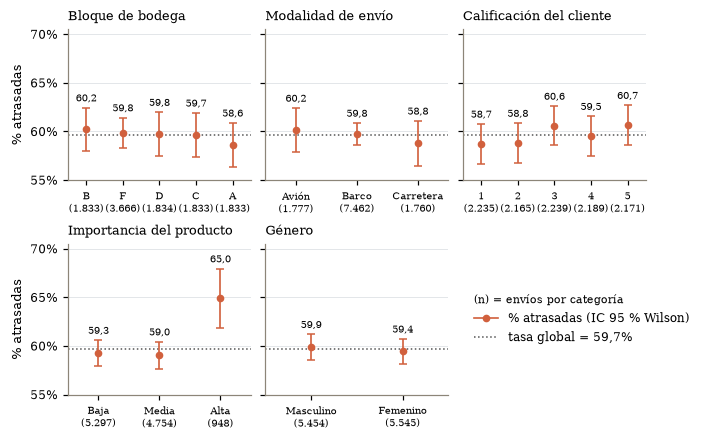

,categorias,tasa_min_%,tasa_max_%,V_cramer
variable,,,,
importancia_producto,3,59.045,64.979,0.033
calificacion_cliente,5,58.747,60.663,0.017
bloque_bodega,5,58.647,60.229,0.010
modalidad_envio,3,58.807,60.158,0.008
genero,2,59.441,59.901,0.005


In [17]:
tasas_cuali = {}
for v in cualitativas:
    t = tasa_por(df[v])
    if not es_ordinal(v):
        t = t.sort_values('tasa', ascending=False)
    tasas_cuali[v] = t
y_min = min(t['li'].min() for t in tasas_cuali.values())
y_max = max(t['ls'].max() for t in tasas_cuali.values())

fig, ax, sobrantes = rejilla(len(cualitativas), alto=1.95, sharey=True)
filas_rel = []
for j, (a, v) in enumerate(zip(ax, cualitativas)):
    t = tasas_cuali[v]
    x = np.arange(len(t))
    a.axhline(tasa_global * 100, color=GRIS, ls=':', lw=1)
    a.errorbar(x, t['tasa'], yerr=[t['tasa'] - t['li'], t['ls'] - t['tasa']], fmt='o', ms=4,
               color=TERRA, ecolor=TERRA, elinewidth=1.1, capsize=2.5)
    for i, (p, ls) in enumerate(zip(t['tasa'], t['ls'])):
        a.text(i, ls + 0.4, num(p, 1), ha='center', va='bottom', fontsize=6.5)
    a.set_xticks(x, [f'{c}\n({num(m)})' for c, m in zip(etiq_cat(v, t.index), t['n'])], fontsize=6.5)
    a.set_xlim(-0.5, len(t) - 0.5)
    a.set_ylim(np.floor(y_min) - 1, np.ceil(y_max) + 2.5)
    a.yaxis.set_major_formatter(FMT_PCT)
    a.set_title(etiq(v), fontsize=8.5)
    a.set_ylabel('% atrasadas' if j % 3 == 0 else '')
    a.grid(axis='x', visible=False)

    tabla = pd.crosstab(df[v], df[TARGET])
    media = df.groupby(v, observed=True)[TARGET].mean()
    filas_rel.append({'variable': v, 'categorias': len(tabla),
                      'tasa_min_%': media.min() * 100, 'tasa_max_%': media.max() * 100,
                      'V_cramer': association(tabla.values, method='cramer')})
sobrantes[0].axis('off')
sobrantes[0].legend(handles=[
    Line2D([], [], color=TERRA, marker='o', ms=4, lw=1.1, label='% atrasadas (IC 95 % Wilson)'),
    Line2D([], [], color=GRIS, ls=':', lw=1, label=f'tasa global = {num(tasa_global * 100, 1)}%')],
    loc='center left', title='(n) = envíos por categoría', alignment='left', title_fontsize=7.5)
guardar('fig_eda_8_dependiente_vs_cualitativas')

rel_cuali = pd.DataFrame(filas_rel).set_index('variable').sort_values('V_cramer', ascending=False)
rel_cuali.to_csv(RAIZ / 'outputs/tablas/relacion_dependiente_cualitativas.csv', encoding='utf-8')
rel_cuali.round(3)

#### (f) Interacción descuento × peso
Las dos variables más asociadas al atraso forman bloques nítidos en el *pairplot*. El mapa cruza ambas y
muestra la tasa de atraso de cada combinación (con su tamaño *n*). Una celda con tasa cercana a 100%
indica una regla casi determinista: dentro de ella el resultado no varía (**separación completa**), lo que
conviene tener presente al estimar proporciones o aplicar pruebas en las secciones 2 y 3.

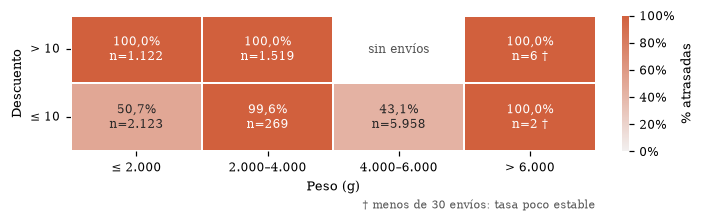

peso_gramos,≤ 2.000,2.000–4.000,4.000–6.000,> 6.000
> 10,100.0,100.0,NaN,100.0
≤ 10,50.7,99.6,43.1,100.0


In [18]:
UMBRAL_DESC = 10
N_MIN_CELDA = 30   # celdas con menos envíos se marcan como poco estables
desc_tramo = np.where(df['descuento_ofrecido'] > UMBRAL_DESC, f'> {UMBRAL_DESC}', f'≤ {UMBRAL_DESC}')
peso_tramo = pd.cut(df['peso_gramos'], [0, 2000, 4000, 6000, np.inf],
                    labels=['≤ 2.000', '2.000–4.000', '4.000–6.000', '> 6.000'])

cruce = df.groupby([desc_tramo, peso_tramo], observed=False)[TARGET].agg(['mean', 'size']).unstack()
tasa_cruce, n_cruce = cruce['mean'] * 100, cruce['size'].fillna(0).astype(int)
anot = tasa_cruce.map(lambda p: '—' if pd.isna(p) else f'{num(p, 1)}%') + n_cruce.map(
    lambda m: f'\nn={num(m)}' + (' †' if 0 < m < N_MIN_CELDA else ''))

fig, ax = plt.subplots(figsize=(ANCHO, 1.9))
sns.heatmap(tasa_cruce, annot=anot, fmt='', annot_kws={'fontsize': 8},
            cmap=sns.light_palette(TERRA, as_cmap=True), vmin=0, vmax=100,
            linewidths=1, linecolor='white', cbar_kws={'label': '% atrasadas', 'format': FMT_PCT}, ax=ax)
for (i, j) in zip(*np.where(n_cruce.to_numpy() == 0)):
    ax.text(j + 0.5, i + 0.5, 'sin envíos', ha='center', va='center', fontsize=8, color=GRIS)
ax.grid(False)
ax.set_xlabel('Peso (g)')
ax.set_ylabel('Descuento')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
if ((n_cruce > 0) & (n_cruce < N_MIN_CELDA)).any().any():
    ax.text(1, -0.42, f'† menos de {N_MIN_CELDA} envíos: tasa poco estable', transform=ax.transAxes,
            ha='right', fontsize=7, color=GRIS)
guardar('fig_eda_9_descuento_x_peso')

tasa_cruce.round(1)

#### (g) Asociación entre las variables cualitativas
Complemento de la matriz de Spearman: *V* de Cramér para cada par de cualitativas. Valores cercanos a 0
indican que las variables no son redundantes entre sí. La escala de color se ajusta al máximo observado
(no a 1) para que las diferencias pequeñas sean visibles; las cifras anotadas son las que se interpretan.

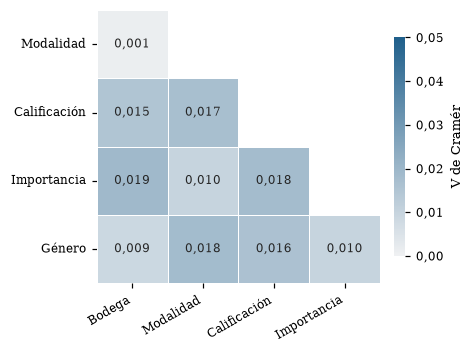

Modalidad de envío por bodega (% de fila):


modalidad_envio,Flight,Road,Ship
bloque_bodega,,,
A,16.2,16.0,67.8
B,16.1,16.0,67.8
C,16.1,16.0,67.9
D,16.2,15.9,67.9
F,16.1,16.0,67.9


In [19]:
cramer = pd.DataFrame(1.0, index=cualitativas, columns=cualitativas)
for i, a in enumerate(cualitativas):
    for b in cualitativas[i + 1:]:
        v = association(pd.crosstab(df[a], df[b]).values, method='cramer')
        cramer.loc[a, b] = cramer.loc[b, a] = v

vista_cramer = cramer.iloc[1:, :-1]
v_max = np.ceil(vista_cramer.where(np.tril(np.ones_like(vista_cramer, dtype=bool))).max().max() * 20) / 20
fig, ax = plt.subplots(figsize=(ANCHO_MEDIO, 3.1))
sns.heatmap(vista_cramer, mask=np.triu(np.ones_like(vista_cramer, dtype=bool), k=1),
            annot=vista_cramer.map(lambda x: num(x, 3)), fmt='', annot_kws={'fontsize': 8},
            cmap=sns.light_palette(AZUL, as_cmap=True), vmin=0, vmax=max(v_max, 0.05),
            linewidths=0.5, cbar_kws={'shrink': 0.8, 'label': 'V de Cramér', 'format': FuncFormatter(lambda x, _: num(x, 2))}, ax=ax)
ax.set_xticklabels([ETIQ_CORTA[c] for c in vista_cramer.columns], rotation=30, ha='right')
ax.set_yticklabels([ETIQ_CORTA[c] for c in vista_cramer.index], rotation=0)
ax.grid(False)
guardar('fig_eda_10_cramer_cualitativas')

print('Modalidad de envío por bodega (% de fila):')
(pd.crosstab(df['bloque_bodega'], df['modalidad_envio'], normalize='index') * 100).round(1)

#### (h) Síntesis del EDA
Cifras clave calculadas a partir de las tablas anteriores (no se escriben a mano):

In [20]:
fuera_diag = lambda m: m.where(~np.eye(len(m), dtype=bool)).abs().stack()
top_cuanti = rel_cuanti['d_cohen'].abs().sort_values(ascending=False)
top_cuali = rel_cuali['V_cramer'].idxmax()
rho = fuera_diag(corr)
v_entre = fuera_diag(cramer)

print(f"Entregas atrasadas                    : {tasa_global*100:.1f}%")
for v in top_cuanti.index[:2]:
    print(f"d de Cohen {v:<27}: {rel_cuanti.loc[v, 'd_cohen']:+.2f}")
top_corr = corr_y['r_punto_biserial'].abs().idxmax()
print(f"Mayor correlación con el atraso       : r_pb = {corr_y.loc[top_corr, 'r_punto_biserial']:+.2f}, "
      f"rho = {corr_y.loc[top_corr, 'rho_spearman']:+.2f} ({top_corr})")
print(f"Mayor V de Cramér con el atraso       : {rel_cuali['V_cramer'].max():.3f} ({top_cuali})")
print(f"Mayor |rho| entre cuantitativas       : {rho.max():.2f} {rho.idxmax()}")
print(f"Mayor V de Cramér entre cualitativas  : {v_entre.max():.3f} {v_entre.idxmax()}")
alto = df[TARGET][df['descuento_ofrecido'] > UMBRAL_DESC]
medio = df[TARGET][df['peso_gramos'].between(2000, 4000, inclusive='right')]
print(f"Atraso con descuento > {UMBRAL_DESC}             : {alto.mean()*100:.1f}% (n = {len(alto):,})")
print(f"Atraso con peso 2.000–4.000 g         : {medio.mean()*100:.1f}% (n = {len(medio):,})")

Entregas atrasadas                    : 59.7%
d de Cohen descuento_ofrecido         : +0.88
d de Cohen peso_gramos                : -0.57
Mayor correlación con el atraso       : r_pb = +0.40, rho = +0.34 (descuento_ofrecido)
Mayor V de Cramér con el atraso       : 0.033 (importancia_producto)
Mayor |rho| entre cuantitativas       : 0.32 ('descuento_ofrecido', 'peso_gramos')
Mayor V de Cramér entre cualitativas  : 0.019 ('bloque_bodega', 'importancia_producto')
Atraso con descuento > 10             : 100.0% (n = 2,647)
Atraso con peso 2.000–4.000 g         : 99.9% (n = 1,788)


**Lectura del EDA**
El atraso afecta a cerca de seis de cada diez registros. Peso y descuento presentan las asociaciones descriptivas más marcadas con el resultado. Con descuento > 10 todos los registros están atrasados; en el tramo (2.000, 4.000] g hay una entrega puntual, por lo que la separación allí es casi completa, no completa. Las asociaciones bivariadas bajas entre predictoras no demuestran independencia conjunta ni ausencia de confusión. Se prioriza una auditoría del origen, temporalidad y composición de estos segmentos, sin formular recomendaciones causales.


## 2. Estimación puntual e intervalos de confianza (ID1.3)

Se estiman los cuatro parámetros definidos en el protocolo (P02 y P03). Intervalos al 95% con la
**aproximación normal** (Teorema Central del Límite):

- Media: $\bar{x} \pm z_{0.975}\cdot s/\sqrt{n}$
- Proporción: $\hat{p} \pm z_{0.975}\cdot\sqrt{\hat{p}(1-\hat{p})/n}$

| Parámetro | Estimador | Intervalo |
|---|---|---|
| Proporción de entregas atrasadas $p$ | $\hat p$ = atrasadas / registros válidos | Normal para una proporción |
| Peso medio $\mu_{peso}$ | $\bar x$ de `peso_gramos` | Normal para una media |
| Costo medio $\mu_{costo}$ | $\bar x$ de `costo_producto` | Normal para una media |
| Llamadas medias $\mu_{llamadas}$ | $\bar x$ de `llamadas_atencion` | Normal para una media (variable de conteo) |

El **95 % caracteriza el procedimiento**: si repitiéramos el muestreo y la construcción del intervalo bajo los mismos supuestos, aproximadamente el 95 % de los intervalos contendría el parámetro fijo. Una vez calculado este intervalo, el parámetro no se vuelve aleatorio; no se le asigna una probabilidad del 95 % de estar dentro. Tampoco es un rango que contenga el 95 % de los envíos. La interpretación requiere independencia y un proceso generador comparable.

In [21]:
from scipy import stats

from statsmodels.stats.proportion import proportion_confint

NIVEL = 0.95
z975 = stats.norm.ppf(1 - (1 - NIVEL) / 2)


def ic_media(x):
    """Media e IC normal (TCL) con los registros válidos."""
    x = pd.Series(x).dropna()
    m, ee = x.mean(), x.std(ddof=1) / np.sqrt(len(x))
    return {'estimacion': m, 'ee': ee, 'ic_inf': m - z975 * ee, 'ic_sup': m + z975 * ee, 'n': len(x)}


def ic_proporcion(x):
    """Proporción de una variable binaria e IC de Wilson al 95 %."""
    x = pd.Series(x).dropna()

    if not x.isin([0, 1]).all():
        raise ValueError(
            'Se requiere una variable binaria codificada 0/1.'
        )

    nn, k = len(x), int(x.sum())
    phat = k / nn

    ee_descriptivo = np.sqrt(phat * (1 - phat) / nn)

    li, ls = proportion_confint(
        k,
        nn,
        alpha=1 - NIVEL,
        method='wilson'
    )

    return {
        'estimacion': phat,
        'ee': ee_descriptivo,
        'ic_inf': li,
        'ic_sup': ls,
        'n': nn
    }


print(f"z_0.975 = {z975:.4f}")

z_0.975 = 1.9600


### 2.1 Proporción de entregas atrasadas (P02)
Se utiliza **Wilson (score binomial)**, especialmente adecuado para mantener los límites dentro de [0, 1] y evitar intervalos degenerados cuando hay proporciones extremas. Se informan éxitos, fracasos y tamaño de muestra; las observaciones deben ser independientes. Los conteos grandes se documentan descriptivamente, pero no constituyen una condición para aplicar Wilson.

In [22]:
pr = ic_proporcion(df[TARGET])
exitos, fracasos = pr['n'] * pr['estimacion'], pr['n'] * (1 - pr['estimacion'])
assert min(exitos, fracasos) >= 10      # condición para la aproximación normal

print(f"Registros válidos (n) : {pr['n']:,}")
print(f"n·p̂ = {exitos:,.0f}   n·(1-p̂) = {fracasos:,.0f}  (ambos ≥ 10)")
print(f"Proporción estimada   : {pr['estimacion']:.4f}   EE = {pr['ee']:.4f}")
print(f"IC 95%                : [{pr['ic_inf']:.4f}; {pr['ic_sup']:.4f}]   ancho = {pr['ic_sup'] - pr['ic_inf']:.4f}")

Registros válidos (n) : 10,999
n·p̂ = 6,563   n·(1-p̂) = 4,436  (ambos ≥ 10)
Proporción estimada   : 0.5967   EE = 0.0047
IC 95%                : [0.5875; 0.6058]   ancho = 0.0183


### 2.2 Medias de peso, costo y llamadas (P03)
**Supuestos del TCL.** La media muestral es aproximadamente normal aunque la variable no lo sea, siempre
que las observaciones sean independientes, la varianza sea finita y no haya valores que dominen la media.
Se revisa para cada variable: *n* efectivo, asimetría, extremos por la regla del IQR y el peso del 1% de
valores más altos en la suma total. El peso es **bimodal** (sección 1.5): la media es un parámetro válido,
pero cae entre las dos modas, por lo que se informa también la mediana como referencia descriptiva.

In [23]:
MEDIAS = {'peso_gramos': 'gramos', 'costo_producto': 'USD', 'llamadas_atencion': 'llamadas'}

filas_sup = []
for v in MEDIAS:
    s = df[v].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    top1 = s.nlargest(max(1, len(s) // 100)).sum() / s.sum() * 100
    filas_sup.append({'variable': v, 'n_efectivo': len(s), 'faltantes': int(df[v].isna().sum()),
                      'valores_distintos': s.nunique(), 'asimetria': s.skew(), 'curtosis_exceso': s.kurt(),
                      'extremos_IQR': int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
                      '%_suma_top1%': top1, 'media': s.mean(), 'mediana': s.median()})
supuestos_ic = pd.DataFrame(filas_sup).set_index('variable')
supuestos_ic.to_csv(RAIZ / 'outputs/tablas/supuestos_intervalos.csv')
supuestos_ic.round(2)

,n_efectivo,faltantes,valores_distintos,asimetria,curtosis_exceso,extremos_IQR,%_suma_top1%,media,mediana
variable,,,,,,,,,
peso_gramos,10999,0,4034,-0.25,-1.45,0,1.65,3634.02,4149.0
costo_producto,10999,0,215,-0.16,-0.97,0,1.45,210.20,214.0
llamadas_atencion,10999,0,6,0.39,-0.31,0,1.71,4.05,4.0


In [24]:
PARAMETRO = {'peso_gramos': 'Peso medio', 'costo_producto': 'Costo medio',
             'llamadas_atencion': 'Llamadas medias'}

filas_ic = [{'parametro': 'Proporción de entregas atrasadas', 'variable': TARGET,
             'estimador': 'proporción muestral', 'unidad': 'proporción',
             'metodo': 'Wilson (score)', **ic_proporcion(df[TARGET])}]
for v, unidad in MEDIAS.items():
    filas_ic.append({'parametro': PARAMETRO[v], 'variable': v, 'estimador': 'media muestral',
                     'unidad': unidad, 'metodo': 'Normal (TCL)', **ic_media(df[v])})

tabla_ic = pd.DataFrame(filas_ic).set_index('parametro')
tabla_ic['ancho'] = tabla_ic['ic_sup'] - tabla_ic['ic_inf']
tabla_ic['ancho_relativo_%'] = tabla_ic['ancho'] / tabla_ic['estimacion'] * 100
tabla_ic = tabla_ic[['variable', 'estimador', 'unidad', 'metodo', 'n', 'estimacion', 'ee',
                     'ic_inf', 'ic_sup', 'ancho', 'ancho_relativo_%']]
tabla_ic.to_csv(RAIZ / 'outputs/tablas/intervalos_confianza.csv', encoding='utf-8')
tabla_ic.round(4)

,variable,estimador,unidad,metodo,n,estimacion,ee,ic_inf,ic_sup,ancho,ancho_relativo_%
parametro,,,,,,,,,,,
Proporción de entregas atrasadas,entrega_atrasada,proporción muestral,proporción,Wilson (score),10999,0.5967,0.0047,0.5875,0.6058,0.0183,3.0724
Peso medio,peso_gramos,media muestral,gramos,Normal (TCL),10999,3634.0167,15.5934,3603.4542,3664.5793,61.1251,1.6820
Costo medio,costo_producto,media muestral,USD,Normal (TCL),10999,210.1968,0.4583,209.2986,211.0951,1.7964,0.8547
Llamadas medias,llamadas_atencion,media muestral,llamadas,Normal (TCL),10999,4.0545,0.0109,4.0331,4.0758,0.0427,1.0523


### 2.3 Interpretación
Cada línea resume parámetro, estimación, intervalo, *n* efectivo y método (generado desde `tabla_ic`).

In [25]:
for param, f in tabla_ic.iterrows():
    if f['unidad'] == 'proporción':
        est, li, ls = (f'{100 * f[c]:.1f}%' for c in ('estimacion', 'ic_inf', 'ic_sup'))
    else:
        est, li, ls = (f"{f[c]:,.2f} {f['unidad']}" for c in ('estimacion', 'ic_inf', 'ic_sup'))
    print(f"- {param}: {est}; intervalo individual del 95 % [{li}; {ls}] "
          f"(n = {f['n']:,}, {f['metodo']}).")

- Proporción de entregas atrasadas: 59.7%; intervalo individual del 95 % [58.7%; 60.6%] (n = 10,999, Wilson (score)).
- Peso medio: 3,634.02 gramos; intervalo individual del 95 % [3,603.45 gramos; 3,664.58 gramos] (n = 10,999, Normal (TCL)).
- Costo medio: 210.20 USD; intervalo individual del 95 % [209.30 USD; 211.10 USD] (n = 10,999, Normal (TCL)).
- Llamadas medias: 4.05 llamadas; intervalo individual del 95 % [4.03 llamadas; 4.08 llamadas] (n = 10,999, Normal (TCL)).


**Figura de los intervalos.** Cada panel muestra la estimación puntual y su IC al 95 % sobre una
escala común de ±3 % del valor estimado, de modo que el largo de cada barra es comparable entre
parámetros con unidades distintas (equivale al ancho relativo de la tabla).

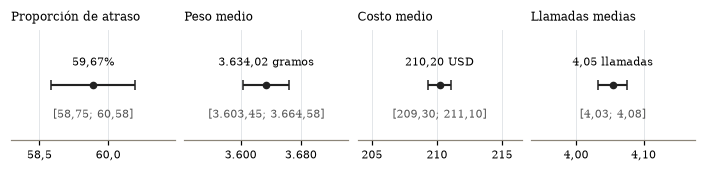

In [26]:
ESCALA_REL = 0.03
fig, ax = plt.subplots(1, len(tabla_ic), figsize=(ANCHO, 1.45), sharey=True)
for a, (param, f) in zip(ax, tabla_ic.iterrows()):
    prop = f['unidad'] == 'proporción'
    factor, sufijo = (100, '%') if prop else (1, f" {f['unidad']}")
    dec, dec_eje = 2, (1 if prop else 2 if f['estimacion'] < 10 else 0)
    est, li, ls = (f[c] * factor for c in ('estimacion', 'ic_inf', 'ic_sup'))
    a.errorbar(est, 0, xerr=[[est - li], [ls - est]], fmt='o', ms=4, color='#222222', elinewidth=1.4,
               capsize=3)
    a.set_xlim(est * (1 - ESCALA_REL), est * (1 + ESCALA_REL))
    a.set_ylim(-1, 1)
    a.set_yticks([])
    a.spines['left'].set_visible(False)
    a.grid(axis='y', visible=False)
    a.set_title({'Proporción de entregas atrasadas': 'Proporción de atraso'}.get(param, param), fontsize=8)
    a.text(est, 0.35, f'{num(est, dec)}{sufijo}', ha='center', fontsize=7.5)
    a.text(est, -0.6, f'[{num(li, dec)}; {num(ls, dec)}]', ha='center', fontsize=7, color=GRIS)
    a.xaxis.set_major_locator(plt.MaxNLocator(3))
    a.xaxis.set_major_formatter(FuncFormatter(lambda x, _, d=dec_eje: num(x, d)))
    a.tick_params(axis='x', labelsize=7)
guardar('fig_inf_1_intervalos')

**Lectura de los intervalos**
El ancho relativo va aproximadamente de 0,85 % a 3,07 % de la estimación. El 95 % es cobertura del procedimiento, condicionado a los supuestos, y no una garantía de representatividad. Para la proporción global se emplea Wilson; para las tres medias se documentan tamaño, forma, extremos y concentración de la suma en `supuestos_intervalos.csv`. La independencia no puede verificarse con estas columnas. El peso es bimodal: ni la media ni la mediana describen por sí solas los dos grupos de valores; se interpretan junto al histograma. Todos los IC son individuales, sin ajuste por multiplicidad.


**Elección del método.** Las proporciones (globales y por subgrupo) emplean intervalos de Wilson al 95 %. Para medias se mantiene la aproximación normal basada en el TCL y para diferencias de medias, intervalos t de Welch con grados de libertad de Welch-Satterthwaite. Los intervalos de diferencias entre proporciones son un problema distinto y no se obtienen restando extremos de Wilson; su método se documenta por separado. La independencia y representatividad no quedan garantizadas por un tamaño muestral grande.


## 3. Pruebas de hipótesis (ID1.4)
Se utiliza α = 0,05 como tolerancia al error de tipo I antes del ajuste. Las comparaciones de medias y proporciones son bilaterales; χ² contrasta independencia.
Las diferencias de medias se calculan como **atrasadas − puntuales**.
El plan inicial incluía modalidad, peso y costo. Durante el EDA se añadió descuento y se reorganizaron los códigos: T03 es descuento y E4 conserva costo. El cambio y E1–E3 son exploratorios; no se declaran preespecificados antes de observar los datos. Se mantiene una sola familia de siete pruebas para Holm. El ajuste controla multiplicidad de esa familia, pero no corrige selección de hipótesis o umbrales a partir del EDA.


In [27]:
ALFA = 0.05


def fmt_p(p):
    return '< 0.0001' if p < 1e-4 else f'= {p:.4f}'


def decision(p):
    return 'se rechaza H0' if p < ALFA else 'no se rechaza H0'


def contraste_welch(x_atr, x_punt):
    """t de Welch bilateral para media(atrasadas) − media(puntuales), con IC y d_av."""
    x_atr, x_punt = pd.Series(x_atr).dropna(), pd.Series(x_punt).dropna()
    r = stats.ttest_ind(x_atr, x_punt, equal_var=False)
    ic = r.confidence_interval(NIVEL)
    dif = x_atr.mean() - x_punt.mean()
    return {'n_atr': len(x_atr), 'media_atr': x_atr.mean(), 'de_atr': x_atr.std(ddof=1),
            'n_punt': len(x_punt), 'media_punt': x_punt.mean(), 'de_punt': x_punt.std(ddof=1),
            'diferencia': dif, 'ic_inf': ic.low, 'ic_sup': ic.high,
            't': r.statistic, 'gl': r.df, 'p': r.pvalue,
            'd_av': dif / np.sqrt((x_atr.var(ddof=1) + x_punt.var(ddof=1)) / 2)}


def z_dos_proporciones(y1, y0):
    """z bilateral para p1 − p0 (EE con proporción combinada) e IC normal de la diferencia (EE no combinado)."""
    y1, y0 = pd.Series(y1).dropna(), pd.Series(y0).dropna()
    n1, n0, p1, p0 = len(y1), len(y0), y1.mean(), y0.mean()
    p_comb = (y1.sum() + y0.sum()) / (n1 + n0)
    z = (p1 - p0) / np.sqrt(p_comb * (1 - p_comb) * (1 / n1 + 1 / n0))
    ee = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
    return {'n1': n1, 'p1': p1, 'n0': n0, 'p0': p0, 'diferencia': p1 - p0,
            'ic_inf': p1 - p0 - z975 * ee, 'ic_sup': p1 - p0 + z975 * ee,
            'z': z, 'p': 2 * stats.norm.sf(abs(z)), 'riesgo_relativo': p1 / p0}

### T01 Asociación entre modalidad de envío y atraso (χ² de independencia)

- $H_0$: la modalidad de envío y el resultado de la entrega son independientes.
- $H_1$: existe asociación entre ambas variables.

Estadístico $\chi^2 = \sum (O - E)^2 / E$, con $E = (\text{total fila} \times \text{total columna}) / n$ y
$gl = (r-1)(c-1) = 2$. Magnitud: $V = \sqrt{\chi^2 \big/ \left(n\,\min(r-1,\,c-1)\right)}$ (V de Cramér).

#### Supuestos
- **Frecuencias esperadas**: todas $\geq 5$. Si alguna fallara se justificaría una alternativa válida; no se
  fusionan modalidades para obtener significancia.
- **Independencia**: cada envío está en una sola celda. La independencia entre registros es un supuesto de
  diseño y no se puede verificar con los datos (protocolo §3).
- **Volumen y proporción**: la tabla separa el número de envíos de la proporción de atraso dentro de cada modalidad.

In [28]:
VAR_T01 = 'modalidad_envio'
columnas = [ETIQ_TARGET[0], ETIQ_TARGET[1]]
observada = pd.crosstab(df[VAR_T01], df[TARGET].map(ETIQ_TARGET))[columnas]

chi2, p_chi, gl, esp = stats.chi2_contingency(observada)
esperada = pd.DataFrame(esp, index=observada.index, columns=observada.columns)

tasas = observada.assign(n=observada.sum(axis=1))
tasas['% atrasadas'] = tasas[ETIQ_TARGET[1]] / tasas['n'] * 100

print('Frecuencias observadas y tasa de atraso por modalidad:')
print(tasas.round(1).to_string())
print('\nFrecuencias esperadas bajo independencia:')
print(esperada.round(1).to_string())
print(f"\nFrecuencia esperada mínima: {esperada.values.min():.1f}  "
      f"(celdas con E < 5: {int((esperada.values < 5).sum())} de {esperada.size})")
print(f"Unidades: {int(observada.values.sum()):,} envíos, cada uno en una sola celda")

Frecuencias observadas y tasa de atraso por modalidad:
entrega_atrasada  A tiempo (0)  Atrasada (1)     n  % atrasadas
modalidad_envio                                                
Flight                     708          1069  1777         60.2
Road                       725          1035  1760         58.8
Ship                      3003          4459  7462         59.8

Frecuencias esperadas bajo independencia:
entrega_atrasada  A tiempo (0)  Atrasada (1)
modalidad_envio                             
Flight                   716.7        1060.3
Road                     709.8        1050.2
Ship                    3009.5        4452.5

Frecuencia esperada mínima: 709.8  (celdas con E < 5: 0 de 6)
Unidades: 10,999 envíos, cada uno en una sola celda


In [29]:
n_t01 = int(observada.values.sum())
v_cramer = np.sqrt(chi2 / (n_t01 * (min(observada.shape) - 1)))
assert np.isclose(v_cramer, association(observada.values, method='cramer'))
residuos = (observada - esperada) / np.sqrt(esperada)    # residuos de Pearson

print(f"χ² = {chi2:.3f}   gl = {gl}   valor p {fmt_p(p_chi)}")
print(f"V de Cramér = {v_cramer:.4f}")
print('Decisión preliminar (sin ajuste):', decision(p_chi))
print('\nResiduos de Pearson (O − E) / √E:')
print(residuos.round(2).to_string())

contraste_modalidad = pd.DataFrame([{
    'codigo': 'T01', 'contraste': 'Asociación entre modalidad de envío y atraso',
    'h0': 'Independencia', 'h1': 'Asociación', 'metodo': 'χ² de independencia',
    'variable': VAR_T01, 'n': n_t01, 'chi2': chi2, 'gl': gl, 'p': p_chi,
    'v_cramer': v_cramer, 'frec_esperada_min': esperada.values.min(),
    'alfa': ALFA, 'decision_sin_ajuste': decision(p_chi)}])
contraste_modalidad.to_csv(RAIZ / 'outputs/tablas/contraste_modalidad.csv', index=False, encoding='utf-8')
contraste_modalidad.T

χ² = 0.743   gl = 2   valor p = 0.6895
V de Cramér = 0.0082
Decisión preliminar (sin ajuste): no se rechaza H0

Residuos de Pearson (O − E) / √E:
entrega_atrasada  A tiempo (0)  Atrasada (1)
modalidad_envio                             
Flight                   -0.32          0.27
Road                      0.57         -0.47
Ship                     -0.12          0.10


,0
codigo,T01
contraste,Asociación entre modalidad de envío y atraso
h0,Independencia
h1,Asociación
metodo,χ² de independencia
variable,modalidad_envio
n,10999
chi2,0.743436
gl,2
p,0.689549


In [30]:
t_min, t_max = tasas['% atrasadas'].min(), tasas['% atrasadas'].max()
print(f"- La tasa de atraso es casi la misma en las tres modalidades: de {t_min:.1f}% "
      f"({tasas['% atrasadas'].idxmin()}) a {t_max:.1f}% ({tasas['% atrasadas'].idxmax()}).")
print(f"- χ² = {chi2:.2f}, gl = {gl}, p {fmt_p(p_chi)}: {decision(p_chi)} (preliminar, antes de Holm).")
print(f"- Magnitud: V de Cramér = {v_cramer:.3f}, asociación prácticamente nula.")

- La tasa de atraso es casi la misma en las tres modalidades: de 58.8% (Road) a 60.2% (Flight).
- χ² = 0.74, gl = 2, p = 0.6895: no se rechaza H0 (preliminar, antes de Holm).
- Magnitud: V de Cramér = 0.008, asociación prácticamente nula.


**Lectura.**

- **Resultado**: los datos no aportan evidencia de asociación entre modalidad y atraso. No rechazar $H_0$ no
  demuestra que sean independientes; con *n* ≈ 11.000 una asociación de magnitud relevante se habría detectado,
  y $V \approx 0{,}008$ indica una magnitud despreciable.
- **Volumen y proporción**: Ship concentra el 67,8% de los envíos y, por eso, la mayoría de los atrasos, pero su
  proporción de atraso (59,8%) es igual a la de las otras modalidades.
- **Supuestos**: todas las frecuencias esperadas superan 700; la independencia entre registros no es verificable.
- **Alcance**: es una asociación observacional; no se fusionaron ni recodificaron modalidades.
- La decisión final depende del *p* ajustado por Holm.

### T02 Diferencia de peso medio entre entregas atrasadas y puntuales (Welch)

Sea $\Delta_{peso} = \mu_{atrasadas} - \mu_{puntuales}$ (en gramos):

- $H_0:\ \Delta_{peso} = 0$
- $H_1:\ \Delta_{peso} \neq 0$

Se usa la prueba *t* de **Welch** porque no supone varianzas iguales y es robusta con grupos de distinto
tamaño: $t = (\bar x_{atr} - \bar x_{punt}) \big/ \sqrt{s_{atr}^2/n_{atr} + s_{punt}^2/n_{punt}}$, con grados
de libertad de Welch-Satterthwaite.

#### Supuestos
- **Tamaños**: *n* de cada grupo.
- **Distribución**: forma del peso en cada grupo (la sección 1.5 mostró que es bimodal).
- **Dispersión**: desviaciones estándar y razón de varianzas (Welch no exige que sean iguales).
- **Independencia**: grupos disjuntos (cada envío pertenece a un solo grupo) e `id_envio` único. La
  independencia entre registros no es verificable con los datos: es un supuesto de diseño (protocolo §3).
- **Influencia**: cambio máximo de la diferencia al quitar una observación, $|x_i - \bar x_g|/(n_g - 1)$, y
  sensibilidad sin los extremos IQR de cada grupo (solo informativo: no se eliminan, protocolo §10).

In [31]:
VAR_T02 = 'peso_gramos'
atr = df.loc[df[TARGET] == 1, VAR_T02]
punt = df.loc[df[TARGET] == 0, VAR_T02]


def es_extremo(x):
    q1, q3 = x.quantile([0.25, 0.75])
    return (x < q1 - 1.5 * (q3 - q1)) | (x > q3 + 1.5 * (q3 - q1))


filas_sup = []
for g, x in [(ETIQ_TARGET[1], atr), (ETIQ_TARGET[0], punt)]:
    filas_sup.append({'grupo': g, 'n': len(x), 'media': x.mean(), 'mediana': x.median(),
                      'de': x.std(ddof=1), 'asimetria': x.skew(), 'curtosis_exceso': x.kurt(),
                      'extremos_IQR': int(es_extremo(x).sum()),
                      'influencia_max_g': (x - x.mean()).abs().max() / (len(x) - 1)})
supuestos_t02 = pd.DataFrame(filas_sup).set_index('grupo')

dif = atr.mean() - punt.mean()
dif_sin_ext = atr[~es_extremo(atr)].mean() - punt[~es_extremo(punt)].mean()
print(f"Independencia: grupos disjuntos = {atr.index.intersection(punt.index).empty}, "
      f"id_envio único = {df['id_envio'].is_unique}")
print(f"Razón de varianzas (atr/punt)        : {atr.var() / punt.var():.3f}")
print(f"Diferencia de medias                 : {dif:,.1f} g")
print(f"Máximo cambio al quitar 1 observación: {supuestos_t02['influencia_max_g'].max():.2f} g "
      f"({supuestos_t02['influencia_max_g'].max() / abs(dif) * 100:.3f}% de la diferencia)")
print(f"Diferencia sin extremos IQR          : {dif_sin_ext:,.1f} g (sensibilidad, no se eliminan)")
supuestos_t02.round(2)

Independencia: grupos disjuntos = True, id_envio único = True
Razón de varianzas (atr/punt)        : 1.003
Diferencia de medias                 : -896.0 g
Máximo cambio al quitar 1 observación: 0.71 g (0.080% de la diferencia)
Diferencia sin extremos IQR          : -1,721.1 g (sensibilidad, no se eliminan)


,n,media,mediana,de,asimetria,curtosis_exceso,extremos_IQR,influencia_max_g
grupo,,,,,,,,
Atrasada (1),6563,3272.64,3231.0,1576.15,0.14,-1.38,0,0.70
A tiempo (0),4436,4168.67,4674.0,1573.95,-0.93,-0.64,1046,0.71


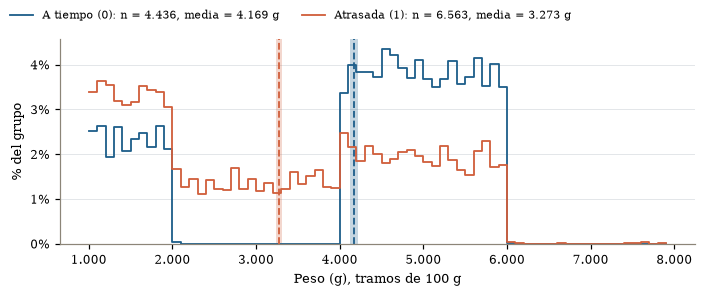

In [32]:
fig, ax = plt.subplots(figsize=(ANCHO, 2.6))
bins = np.arange(1000, df[VAR_T02].max() + 100, 100)
for k, x in [(0, punt), (1, atr)]:
    g = ETIQ_TARGET[k]
    color = PAL_TARGET[g]
    sns.histplot(x, ax=ax, stat='percent', bins=bins, element='step', fill=False, color=color, lw=1.2,
                 label=f'{g}: n = {num(len(x))}, media = {num(x.mean())} g')
    se = x.std(ddof=1) / np.sqrt(len(x))
    ax.axvspan(x.mean() - 1.96 * se, x.mean() + 1.96 * se, color=color, alpha=0.25, lw=0)
    ax.axvline(x.mean(), color=color, lw=1.2, ls='--')
ax.set_xlabel('Peso (g), tramos de 100 g')
ax.set_ylabel('% del grupo')
ax.xaxis.set_major_formatter(FMT_MILES)
ax.yaxis.set_major_formatter(FMT_PCT)
ax.grid(axis='x', visible=False)
fig.legend(loc='outside upper left', ncol=2, fontsize=7.5)
guardar('fig_t02_peso_grupos')

#### Prueba
El intervalo de confianza de la diferencia usa el mismo error estándar y los mismos grados de libertad de
Welch que el estadístico, por lo que es coherente con la prueba.

In [33]:
t02 = contraste_welch(atr, punt)

print(f"Atrasadas : media = {t02['media_atr']:,.1f} g   DE = {t02['de_atr']:,.1f}   n = {t02['n_atr']:,}")
print(f"Puntuales : media = {t02['media_punt']:,.1f} g   DE = {t02['de_punt']:,.1f}   n = {t02['n_punt']:,}")
print(f"Diferencia (atrasada − puntual): {t02['diferencia']:,.1f} g")
print(f"IC 95% de la diferencia        : [{t02['ic_inf']:,.1f}; {t02['ic_sup']:,.1f}] g")
print(f"t de Welch = {t02['t']:.2f}   gl = {t02['gl']:,.1f}   valor p {fmt_p(t02['p'])}")
print('Decisión preliminar (sin ajuste):', decision(t02['p']))

Atrasadas : media = 3,272.6 g   DE = 1,576.1   n = 6,563
Puntuales : media = 4,168.7 g   DE = 1,574.0   n = 4,436
Diferencia (atrasada − puntual): -896.0 g
IC 95% de la diferencia        : [-956.0; -836.0] g
t de Welch = -29.27   gl = 9,526.6   valor p < 0.0001
Decisión preliminar (sin ajuste): se rechaza H0


#### Tamaño de efecto estandarizado
$$d_{av} = \frac{\bar x_{atr} - \bar x_{punt}}{\sqrt{\left(s_{atr}^2 + s_{punt}^2\right)/2}}$$

**Denominador**: raíz del **promedio simple** de las dos varianzas muestrales (no ponderado por *n*), según
el protocolo §8. Mantiene el signo de la diferencia (negativo = las atrasadas pesan menos) y expresa la
diferencia en desviaciones estándar. A diferencia de la *d* de Cohen de la sección 1.5, que usa la desviación
combinada ponderada por $n-1$, no da más peso al grupo más grande. No se fijan umbrales de importancia
operacional sin respaldo externo.

In [34]:
d_cohen_eda = rel_cuanti.loc[VAR_T02, 'd_cohen']
print(f"d_av                        = {t02['d_av']:+.3f}")
print(f"d de Cohen (DE ponderada)   = {d_cohen_eda:+.3f}  (sección 1.5, como referencia)")

contraste_peso = pd.DataFrame([{
    'codigo': 'T02', 'contraste': 'Diferencia de peso medio (atrasada − puntual)',
    'h0': 'Δpeso = 0', 'h1': 'Δpeso ≠ 0', 'metodo': 't de Welch bilateral',
    'variable': VAR_T02, 'unidad': 'gramos', **t02, 'alfa': ALFA,
    'decision_sin_ajuste': decision(t02['p']),
    'formula_d_av': '(media_atr - media_punt) / sqrt((var_atr + var_punt) / 2)'}])
contraste_peso.to_csv(RAIZ / 'outputs/tablas/contraste_peso.csv', index=False, encoding='utf-8')
contraste_peso.T

d_av                        = -0.569
d de Cohen (DE ponderada)   = -0.569  (sección 1.5, como referencia)


,0
codigo,T02
contraste,Diferencia de peso medio (atrasada − puntual)
h0,Δpeso = 0
h1,Δpeso ≠ 0
metodo,t de Welch bilateral
variable,peso_gramos
unidad,gramos
n_atr,6563
media_atr,3272.640104
de_atr,1576.148391


#### Interpretación

In [35]:
print(f"- Las entregas atrasadas pesan en promedio {abs(t02['diferencia']):,.0f} g menos que las puntuales "
      f"({t02['media_atr']:,.0f} g frente a {t02['media_punt']:,.0f} g).")
print(f"- Con 95% de confianza, la diferencia poblacional está entre {t02['ic_inf']:,.0f} y {t02['ic_sup']:,.0f} g; "
      f"el intervalo no incluye 0.")
print(f"- t = {t02['t']:.2f}, gl = {t02['gl']:,.0f}, p {fmt_p(t02['p'])}: {decision(t02['p'])} (preliminar, antes de Holm).")
print(f"- Magnitud: d_av = {t02['d_av']:+.2f}, es decir, la diferencia equivale a {abs(t02['d_av']):.2f} "
      f"desviaciones estándar.")

- Las entregas atrasadas pesan en promedio 896 g menos que las puntuales (3,273 g frente a 4,169 g).
- Con 95% de confianza, la diferencia poblacional está entre -956 y -836 g; el intervalo no incluye 0.
- t = -29.27, gl = 9,527, p < 0.0001: se rechaza H0 (preliminar, antes de Holm).
- Magnitud: d_av = -0.57, es decir, la diferencia equivale a 0.57 desviaciones estándar.


**Lectura.**

- **Magnitud y significancia**: la diferencia es grande en gramos y en unidades estandarizadas; con *n* ≈
  11.000 incluso diferencias pequeñas serían significativas, por eso se reporta la magnitud junto al valor *p*.
- **Supuestos**: ambos grupos son grandes, sin colas pesadas y con dispersión casi idéntica, y ninguna
  observación individual mueve la diferencia de forma apreciable (< 1 g). El TCL respalda la normalidad
  aproximada de las medias pese a la bimodalidad.
- **Sensibilidad**: los extremos IQR de las puntuales son los envíos livianos (≤ 2.000 g), extremos solo
  dentro de ese grupo. Al excluirlos, la diferencia casi se duplica, pero mantiene el signo. Son valores
  válidos y se conservan (protocolo §10); la sensibilidad indica que la **magnitud** de la diferencia
  depende de la mezcla de pesos livianos en cada grupo, mientras que la **dirección** es robusta.
- **Alcance**: la diferencia de medias resume un patrón **no monótono** (sección 1.5: el tramo de 2.000–4.000 g
  concentra casi todos los atrasos y el de 4.000–6.000 g tiene la menor tasa). No implica que "más peso
  cause menos atraso", ni que el efecto sea lineal; es una asociación observacional.
- La decisión final depende del *p* ajustado por Holm en la familia de 7 pruebas.

### T03 Diferencia de descuento medio entre entregas atrasadas y puntuales (Welch)

- $H_0:\mu_{atrasadas}-\mu_{puntuales}=0$.
- $H_1:\mu_{atrasadas}-\mu_{puntuales}\ne0$.
- Welch bilateral, $\alpha=0{,}05$, diferencia atrasadas menos puntuales, IC del 95 % y $d_{av}$.
- La unidad de `descuento_ofrecido` **no está acreditada**; se reporta en unidades originales, nunca en porcentajes. Los identificadores únicos no prueban independencia probabilística.

In [36]:
VAR_T03 = 'descuento_ofrecido'
desc_atr = df.loc[df[TARGET] == 1, VAR_T03].dropna()
desc_punt = df.loc[df[TARGET] == 0, VAR_T03].dropna()
assert len(desc_atr)>1 and len(desc_punt)>1
assert desc_atr.index.intersection(desc_punt.index).empty
supuestos_t03 = pd.DataFrame([{'grupo': et, 'n':len(x), 'media':x.mean(), 'mediana':x.median(), 'de':x.std(ddof=1), 'asimetria':x.skew(), 'extremos_IQR':int(es_extremo(x).sum())} for et,x in [(ETIQ_TARGET[1],desc_atr),(ETIQ_TARGET[0],desc_punt)]]).set_index('grupo')
t03 = contraste_welch(desc_atr, desc_punt)
print('Supuesto de independencia entre envíos: no verificable solo con ID. Se retienen valores extremos.')
print('Razón de varianzas:', round(desc_atr.var(ddof=1)/desc_punt.var(ddof=1),3))
display(supuestos_t03.round(2))

Supuesto de independencia entre envíos: no verificable solo con ID. Se retienen valores extremos.
Razón de varianzas: 44.093


,n,media,mediana,de,asimetria,extremos_IQR
grupo,,,,,,
Atrasada (1),6563,18.66,9.0,19.11,1.05,0
A tiempo (0),4436,5.55,6.0,2.88,-0.01,0


#### Resultado e interpretación de T03

El IC de la diferencia utiliza Welch-Satterthwaite y el tamaño de efecto $d_{av}$ utiliza la raíz de la media de las varianzas muestrales. La significancia estadística no demuestra que el descuento cause el atraso. El significado comercial de la escala de descuento sigue pendiente de verificación.

In [37]:
print(f"Atrasadas: n={t03['n_atr']:,}, media={t03['media_atr']:.2f}, DE={t03['de_atr']:.2f}")
print(f"Puntuales: n={t03['n_punt']:,}, media={t03['media_punt']:.2f}, DE={t03['de_punt']:.2f}")
print(f"Diferencia (unidades originales): {t03['diferencia']:+.2f}")
print(f"IC 95 % diferencia: [{t03['ic_inf']:+.2f}; {t03['ic_sup']:+.2f}]")
print(f"t={t03['t']:.3f}, gl={t03['gl']:.1f}, p={t03['p']:.6g}, d_av={t03['d_av']:+.3f}")
print('Decisión sin ajuste:', decision(t03['p']))
print('Asociación observacional, no causalidad.')
fila_t03={'codigo':'T03','prueba':'Welch: descuento medio atrasadas vs puntuales','variable':VAR_T03,'unidad':'unidades originales, no documentadas',**t03,'decision_sin_ajuste':decision(t03['p'])}
pd.DataFrame([fila_t03]).to_csv(RAIZ/'outputs/tablas/contraste_descuento.csv',index=False)

Atrasadas: n=6,563, media=18.66, DE=19.11
Puntuales: n=4,436, media=5.55, DE=2.88
Diferencia (unidades originales): +13.12
IC 95 % diferencia: [+12.65; +13.59]
t=54.703, gl=6998.1, p=0, d_av=+0.960
Decisión sin ajuste: se rechaza H0
Asociación observacional, no causalidad.


#### Figura T03: descuento ofrecido según resultado de entrega

Función de distribución acumulada empírica (ECDF) del descuento por grupo, en unidades originales. Se
prefiere a un diagrama de caja porque la variable es muy asimétrica y la diferencia entre grupos está
justamente en la cola: ningún envío puntual supera el umbral de 10, mientras que una parte importante de
los atrasados sí lo hace. No se oculta ningún valor.

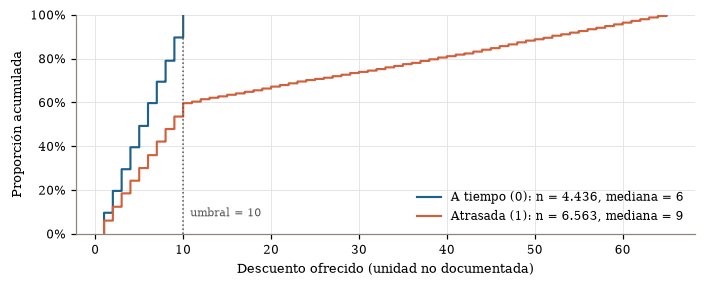

In [38]:
fig, ax = plt.subplots(figsize=(ANCHO, 2.5))
for k, x in [(0, desc_punt), (1, desc_atr)]:
    g = ETIQ_TARGET[k]
    sns.ecdfplot(x, ax=ax, color=PAL_TARGET[g], lw=1.4,
                 label=f'{g}: n = {num(len(x))}, mediana = {num(x.median())}')
ax.axvline(UMBRAL_DESC, color=GRIS, ls=':', lw=1)
ax.text(UMBRAL_DESC + 0.8, 0.08, f'umbral = {UMBRAL_DESC}', color=GRIS, fontsize=7.5)
ax.set_xlabel('Descuento ofrecido (unidad no documentada)')
ax.set_ylabel('Proporción acumulada')
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f'{num(y * 100)}%'))
ax.legend(loc='lower right')
guardar('fig_t03_descuento_grupos')

#### Figura 6: relaciones cuantitativas seleccionadas

Correlaciones de Spearman entre las variables cuantitativas de interés; excluye el identificador y las
variables categóricas codificadas como números. Es la misma matriz de la figura `fig_eda_5_correlacion`
(sección 1.5 d), por lo que aquí solo se muestra la tabla y no se duplica la figura. La asociación de
rangos no establece causalidad.

In [39]:
variables_fig6 = [v for v in ['costo_producto', 'peso_gramos', 'descuento_ofrecido',
                             'llamadas_atencion', 'compras_previas'] if v in df]
assert set(variables_fig6) == set(cuantitativas)   # misma matriz que fig_eda_5
corr.loc[variables_fig6, variables_fig6].round(3)

,costo_producto,peso_gramos,descuento_ofrecido,llamadas_atencion,compras_previas
costo_producto,1.000,-0.132,-0.116,0.294,0.194
peso_gramos,-0.132,1.000,-0.316,-0.233,-0.235
descuento_ofrecido,-0.116,-0.316,1.000,-0.104,-0.094
llamadas_atencion,0.294,-0.233,-0.104,1.000,0.273
compras_previas,0.194,-0.235,-0.094,0.273,1.000


### Pruebas complementarias E1–E4
Forman parte de la **familia de Holm de 7 pruebas**. Cada una reporta el *p* sin ajustar y una decisión
preliminar.

| Código | Pregunta | Método |
|---|---|---|
| E1 | ¿La distribución del peso difiere entre atrasadas y puntuales? | Mann-Whitney *U* (robustez de T02, no depende de la media) |
| E2 | ¿La tasa de atraso difiere entre productos de importancia alta y el resto? | *z* de dos proporciones |
| E3 | ¿La tasa de atraso difiere entre descuento > 10 y ≤ 10? | *z* de dos proporciones |
| E4 | ¿El descuento medio difiere entre atrasadas y puntuales? | *t* de Welch |

Prueba *z* de dos proporciones: $z = (\hat p_1-\hat p_0)\big/\sqrt{\hat p(1-\hat p)(1/n_1+1/n_0)}$, con
$\hat p$ la proporción combinada; el IC de la diferencia usa el error estándar no combinado
$\sqrt{\hat p_1(1-\hat p_1)/n_1 + \hat p_0(1-\hat p_0)/n_0}$.

#### E1 Mann-Whitney del peso
H₀: las distribuciones del peso son iguales en ambos grupos. H₁: difieren en el sentido detectado por el contraste bilateral de rangos. No es una prueba de igualdad de medianas sin supuestos adicionales de forma. Se usa el método asintótico, con corrección por empates y continuidad; efecto r = 2U/(n_atr n_punt) − 1. La independencia entre registros sigue siendo necesaria.


In [40]:
mw = stats.mannwhitneyu(atr, punt, alternative='two-sided', method='asymptotic', use_continuity=True)
r_rb = 2 * mw.statistic / (len(atr) * len(punt)) - 1

print(f"Mediana atrasadas = {atr.median():,.0f} g   Mediana puntuales = {punt.median():,.0f} g")
print(f"U = {mw.statistic:,.0f}   valor p {fmt_p(mw.pvalue)}   r biserial de rangos = {r_rb:+.3f}")
print('Decisión preliminar (sin ajuste):', decision(mw.pvalue))

Mediana atrasadas = 3,231 g   Mediana puntuales = 4,674 g
U = 10,000,332   valor p < 0.0001   r biserial de rangos = -0.313
Decisión preliminar (sin ajuste): se rechaza H0


#### E2 Tasa de atraso: importancia alta vs. resto
$H_0:\ p_{alta} = p_{resto}$ vs. $H_1:\ p_{alta} \neq p_{resto}$. Es la única cualitativa con una diferencia
visible en la sección 1.5.

In [41]:
alta = df['importancia_producto'] == 'high'
e2 = z_dos_proporciones(df.loc[alta, TARGET], df.loc[~alta, TARGET])

print(f"Importancia alta : {e2['p1']*100:.1f}% atrasadas (n = {e2['n1']:,})")
print(f"Resto            : {e2['p0']*100:.1f}% atrasadas (n = {e2['n0']:,})")
print(f"Diferencia = {e2['diferencia']*100:+.1f} pp   IC 95% [{e2['ic_inf']*100:+.1f}; {e2['ic_sup']*100:+.1f}] pp")
print(f"z = {e2['z']:.2f}   valor p {fmt_p(e2['p'])}   riesgo relativo = {e2['riesgo_relativo']:.2f}")
print('Decisión preliminar (sin ajuste):', decision(e2['p']))

Importancia alta : 65.0% atrasadas (n = 948)
Resto            : 59.2% atrasadas (n = 10,051)
Diferencia = +5.8 pp   IC 95% [+2.6; +9.0] pp
z = 3.49   valor p = 0.0005   riesgo relativo = 1.10
Decisión preliminar (sin ajuste): se rechaza H0


#### E3 Tasa de atraso: descuento > 10 vs. ≤ 10
$H_0:\ p_{>10} = p_{\le 10}$ vs. $H_1:\ p_{>10} \neq p_{\le 10}$. **Advertencia**: hay separación completa
($\hat p_{>10} = 1$), por lo que ese grupo no aporta varianza al error estándar no combinado del IC; el
intervalo refleja solo la incertidumbre del grupo ≤ 10. La prueba *z* (con proporción combinada) sigue
siendo calculable.

In [42]:
desc_alto = df['descuento_ofrecido'] > UMBRAL_DESC
e3 = z_dos_proporciones(df.loc[desc_alto, TARGET], df.loc[~desc_alto, TARGET])

print(f"Descuento > {UMBRAL_DESC} : {e3['p1']*100:.1f}% atrasadas (n = {e3['n1']:,})")
print(f"Descuento ≤ {UMBRAL_DESC} : {e3['p0']*100:.1f}% atrasadas (n = {e3['n0']:,})")
print(f"Diferencia = {e3['diferencia']*100:+.1f} pp   IC 95% [{e3['ic_inf']*100:+.1f}; {e3['ic_sup']*100:+.1f}] pp")
print(f"z = {e3['z']:.2f}   valor p {fmt_p(e3['p'])}   riesgo relativo = {e3['riesgo_relativo']:.2f}")
print('Decisión preliminar (sin ajuste):', decision(e3['p']))

Descuento > 10 : 100.0% atrasadas (n = 2,647)
Descuento ≤ 10 : 46.9% atrasadas (n = 8,352)
Diferencia = +53.1 pp   IC 95% [+52.0; +54.2] pp
z = 48.54   valor p < 0.0001   riesgo relativo = 2.13
Decisión preliminar (sin ajuste): se rechaza H0


#### E4 Diferencia de costo medio entre entregas atrasadas y puntuales (Welch, complementaria)

$H_0:\Delta_{costo}=0$ frente a $H_1:\Delta_{costo}\neq 0$, con $\Delta_{costo}=\mu_{atrasadas}-\mu_{puntuales}$, en USD. Se preserva como prueba complementaria para mantener las siete pruebas sin duplicar T03.

In [43]:

e4 = contraste_welch(
    df.loc[df[TARGET] == 1, 'costo_producto'],
    df.loc[df[TARGET] == 0, 'costo_producto']
)

print(f"Atrasadas media = {e4['media_atr']:.2f} USD; puntuales media = {e4['media_punt']:.2f} USD")
print(f"Diferencia = {e4['diferencia']:.2f} USD, IC 95 % [{e4['ic_inf']:.2f}; {e4['ic_sup']:.2f}]")
print(f"t = {e4['t']:.3f}, gl = {e4['gl']:.1f}, p = {e4['p']:.6g}, d_av = {e4['d_av']:.3f}")
print('Decisión preliminar:', decision(e4['p']))

pd.DataFrame([
    {
        'codigo': 'E4',
        'variable': 'costo_producto',
        'unidad': 'USD',
        **e4
    }
]).to_csv(
    RAIZ / 'outputs/tablas/contraste_costo.csv',
    index=False
)

Atrasadas media = 207.29 USD; puntuales media = 214.50 USD
Diferencia = -7.21 USD, IC 95 % [-9.03; -5.39]
t = -7.747, gl = 9557.2, p = 1.03573e-14, d_av = -0.150
Decisión preliminar: se rechaza H0


#### Resumen de las pruebas complementarias
Exportado a `outputs/tablas/contrastes_complementarios.csv`. Las columnas `codigo` y `p` coinciden con
`contraste_peso.csv`, para consolidar las 7 pruebas y aplicar Holm.

In [44]:
contrastes_compl = pd.DataFrame([
    {'codigo': 'E1', 'prueba': 'Mann-Whitney U: peso atrasadas vs puntuales', 'estadistico': 'U',
     'valor_estadistico': mw.statistic, 'p': mw.pvalue, 'efecto': 'r biserial de rangos', 'valor_efecto': r_rb},
    {'codigo': 'E2', 'prueba': 'z dos proporciones: atraso importancia alta vs resto', 'estadistico': 'z',
     'valor_estadistico': e2['z'], 'p': e2['p'], 'efecto': 'diferencia de proporciones', 'valor_efecto': e2['diferencia']},
    {'codigo': 'E3', 'prueba': f'z dos proporciones: atraso descuento > {UMBRAL_DESC} vs <= {UMBRAL_DESC}', 'estadistico': 'z',
     'valor_estadistico': e3['z'], 'p': e3['p'], 'efecto': 'diferencia de proporciones', 'valor_efecto': e3['diferencia']},
    {'codigo': 'E4', 'prueba': 'Welch: costo medio atrasadas vs puntuales', 'estadistico': 't',
     'valor_estadistico': e4['t'], 'p': e4['p'], 'efecto': 'd_av', 'valor_efecto': e4['d_av']},
])
contrastes_compl['decision_sin_ajuste'] = contrastes_compl['p'].map(decision)
contrastes_compl.to_csv(RAIZ / 'outputs/tablas/contrastes_complementarios.csv', index=False, encoding='utf-8')
contrastes_compl.assign(p=contrastes_compl['p'].map(lambda p: f'{p:.1e}')).round(3)

,codigo,prueba,estadistico,valor_estadistico,p,efecto,valor_efecto,decision_sin_ajuste
0,E1,Mann-Whitney U: peso atrasadas vs puntuales,U,1.000033e+07,3.4e-171,r biserial de rangos,-0.313,se rechaza H0
1,E2,z dos proporciones: atraso importancia alta vs...,z,3.486000e+00,4.9e-04,diferencia de proporciones,0.058,se rechaza H0
2,E3,z dos proporciones: atraso descuento > 10 vs <...,z,4.854000e+01,0.0e+00,diferencia de proporciones,0.531,se rechaza H0
3,E4,Welch: costo medio atrasadas vs puntuales,t,-7.747000e+00,1.0e-14,d_av,-0.150,se rechaza H0


### Consolidación inferencial y Holm
Una sola familia de **siete pruebas**: T01 modalidad, T02 peso, T03 descuento y E1–E4. `multipletests(method='holm', alpha=0.05)` produce los valores p ajustados; las decisiones finales se basan en ellos. No se presenta una familia distinta para favorecer resultados. El carácter exploratorio del cambio de T03 y de las pruebas complementarias queda explícito. Holm no convierte hipótesis elegidas tras observar los datos en confirmatorias.


In [45]:
from statsmodels.stats.multitest import multipletests
principales=pd.DataFrame([
 {'codigo':'T01','prueba':'Chi-cuadrado: modalidad y atraso','p':float(p_chi)},
 {'codigo':'T02','prueba':'Welch: peso medio atrasadas vs puntuales','p':float(t02['p'])},
 {'codigo':'T03','prueba':'Welch: descuento medio atrasadas vs puntuales','p':float(t03['p'])}])
familia_siete=pd.concat([principales,contrastes_compl[['codigo','prueba','p']]],ignore_index=True)
assert familia_siete['codigo'].is_unique and len(familia_siete)==7
familia_siete['p_holm']=multipletests(familia_siete['p'].to_numpy(),alpha=ALFA,method='holm')[1]
familia_siete['decision_holm']=familia_siete['p_holm'].map(decision)
familia_siete.to_csv(RAIZ/'outputs/tablas/contrastes_holm_7.csv',index=False)
principales= familia_siete.loc[familia_siete.codigo.str.startswith('T')].copy()
principales.to_csv(RAIZ/'outputs/tablas/contrastes_consolidados.csv',index=False)
display(familia_siete.assign(p=familia_siete.p.map(lambda x:f'{x:.3g}'),p_holm=familia_siete.p_holm.map(lambda x:f'{x:.3g}')))
assert len(tabla_ic)==4
tabla_ic.to_csv(RAIZ/'outputs/tablas/estimaciones.csv')

,codigo,prueba,p,p_holm,decision_holm
0,T01,Chi-cuadrado: modalidad y atraso,0.69,0.69,no se rechaza H0
1,T02,Welch: peso medio atrasadas vs puntuales,1.93e-180,9.65e-180,se rechaza H0
2,T03,Welch: descuento medio atrasadas vs puntuales,0,0,se rechaza H0
3,E1,Mann-Whitney U: peso atrasadas vs puntuales,3.4e-171,1.36e-170,se rechaza H0
4,E2,z dos proporciones: atraso importancia alta vs...,0.00049,0.00098,se rechaza H0
5,E3,z dos proporciones: atraso descuento > 10 vs <...,0,0,se rechaza H0
6,E4,Welch: costo medio atrasadas vs puntuales,1.04e-14,3.11e-14,se rechaza H0


**Figura Holm.** Se representa −log₁₀(p), con eje logarítmico, y el umbral α = 0,05. Los valores devueltos como cero por precisión finita se ubican en un tope visual de 300; ese tope no es una cota calculada del p verdadero ni indica una probabilidad matemáticamente nula.


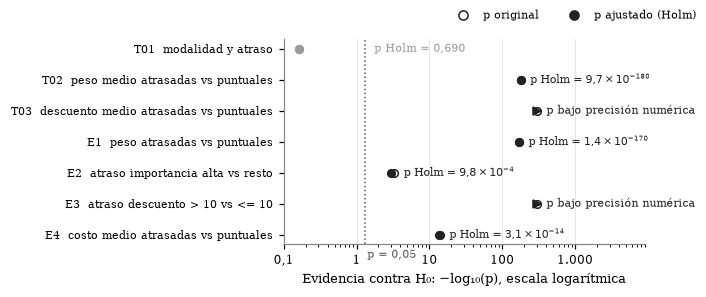

In [46]:
TOPE = 300
evid = lambda p: np.minimum(-np.log10(np.maximum(p, 10.0 ** -TOPE)), TOPE)
holm = familia_siete.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(ANCHO, 2.6))
pos = np.arange(len(holm))
for y, f in holm.iterrows():
    color = '#222222' if f['p_holm'] < ALFA else '#9a9a9a'
    e_raw, e_holm = evid(f['p']), evid(f['p_holm'])
    ax.hlines(y, min(e_raw, e_holm), max(e_raw, e_holm), color=GRID, lw=2.5)
    ax.plot(e_raw, y, 'o', mfc='white', mec=color, ms=5)
    ax.plot(e_holm, y, '>' if f['p_holm'] == 0 else 'o', color=color, ms=5)
    if f['p_holm'] == 0:
        p_txt = 'p bajo precisión numérica'
    elif f['p_holm'] >= 1e-3:
        p_txt = f"p Holm = {num(f['p_holm'], 3)}"
    else:
        mant, expo = f"{f['p_holm']:.1e}".split('e')
        p_txt = rf"p Holm = ${mant.replace('.', '{,}')}\times10^{{{int(expo)}}}$"
    ax.text(max(e_raw, e_holm, -np.log10(ALFA)) * 1.35, y, p_txt, va='center', fontsize=7, color=color)
ax.axvline(-np.log10(ALFA), color=GRIS, ls=':', lw=1)
ax.text(-np.log10(ALFA) * 1.08, -0.75, f'p = {num(ALFA, 2)}', color=GRIS, fontsize=7)
ax.set_xscale('log')
ax.set_xlim(0.1, TOPE * 30)
ax.set_yticks(pos, [f"{c}  {p.split(':')[1].strip()}" for c, p in zip(holm['codigo'], holm['prueba'])],
              fontsize=7.5)
ax.set_xlabel('Evidencia contra H₀: −log₁₀(p), escala logarítmica')
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: num(x, 1 if x < 1 else 0)))
ax.grid(axis='y', visible=False)
fig.legend(handles=[Line2D([], [], marker='o', mfc='white', mec='#222222', ls='', label='p original'),
                   Line2D([], [], marker='o', color='#222222', ls='', label='p ajustado (Holm)')],
          loc='outside upper right', ncol=2, fontsize=7.5)
guardar('fig_inf_2_holm')

## 4. Síntesis, segmentos y trazabilidad
Las tablas siguientes exportan la matriz completa, las dos comparaciones de proporciones y el segmento que debe auditarse. El umbral de descuento 10 se identificó durante el EDA y no se considera una regla general. Las recomendaciones consisten en verificar origen, fechas, campañas y composición de los envíos antes de tomar decisiones operacionales.


In [47]:
corr.to_csv(RAIZ / 'outputs/tablas/correlacion_spearman.csv')
cramer.to_csv(RAIZ / 'outputs/tablas/asociacion_cramer.csv')
supuestos_ic.to_csv(RAIZ / 'outputs/tablas/supuestos_intervalos.csv')
proporciones = pd.DataFrame([{'codigo':'E2','grupo1':'importancia alta','grupo0':'resto',**e2},
                            {'codigo':'E3','grupo1':'descuento > 10','grupo0':'descuento <= 10',**e3}])
proporciones.to_csv(RAIZ / 'outputs/tablas/comparaciones_proporciones.csv', index=False)
segmento = df.groupby(desc_alto)[TARGET].agg(['size','sum','mean'])
segmento.index.name = 'descuento_mayor_10'
segmento['ic_wilson_inf'], segmento['ic_wilson_sup'] = proportion_confint(segmento['sum'], segmento['size'], alpha=0.05, method='wilson')
segmento.to_csv(RAIZ / 'outputs/tablas/segmento_descuento.csv')
assert hashlib.sha256((RAIZ / 'data/raw/ecommerce_shipping.csv').read_bytes()).hexdigest() == HUELLA_INICIAL
import sys, json
entorno = {'python':sys.version.split()[0], 'datos_sha256':HUELLA_INICIAL,
           'paquetes':{p:version(p) for p in ['numpy','pandas','scipy','statsmodels','matplotlib','seaborn']}}
(RAIZ / 'outputs/tablas/entorno_ejecucion.json').write_text(json.dumps(entorno,ensure_ascii=False,indent=2),encoding='utf-8')
print('Original intacto; cuatro intervalos y siete contrastes exportados.')
display(desc[['mean','asimetria','curtosis_exceso']].round(3))
display(corr.round(3))
display(segmento)


Original intacto; cuatro intervalos y siete contrastes exportados.


,mean,asimetria,curtosis_exceso
llamadas_atencion,4.054,0.392,-0.309
costo_producto,210.197,-0.157,-0.972
compras_previas,3.568,1.682,4.006
descuento_ofrecido,13.373,1.799,2.001
peso_gramos,3634.017,-0.250,-1.448


,llamadas_atencion,costo_producto,compras_previas,descuento_ofrecido,peso_gramos
llamadas_atencion,1.000,0.294,0.273,-0.104,-0.233
costo_producto,0.294,1.000,0.194,-0.116,-0.132
compras_previas,0.273,0.194,1.000,-0.094,-0.235
descuento_ofrecido,-0.104,-0.116,-0.094,1.000,-0.316
peso_gramos,-0.233,-0.132,-0.235,-0.316,1.000


,size,sum,mean,ic_wilson_inf,ic_wilson_sup
descuento_mayor_10,,,,,
False,8352,3916,0.46887,0.458184,0.479584
True,2647,2647,1.00000,0.998551,1.000000
